
<div align="center">

# THE INFINITE MAP
### PARIS, FRANCE

*An Atlas of Infinite Detail*

---

**30DayMapChallenge 2026**

**DAY 14 · BORGESIAN MAP**

*Île de la Cité · The Seine · Paris*

---

**THE CENTRAL QUESTION**

*At what point does increasing map detail stop improving our understanding of the city?*

---

**Cartography & Spatial Analysis**

Alhaylam Alajmi

University of Pennsylvania · MUSA

November 14, 2026

</div>



## 01 | Project Overview

### Mapping the Infinite City

Inspired by Jorge Luis Borges' *On Exactitude in Science*, this project explores how increasing geographic detail changes the way we understand urban space.

The study focuses on **Île de la Cité and the surrounding Seine riverbanks in Paris**, where historic streets, buildings, and public spaces create a complex urban landscape.

Rather than presenting a single static map, the project progressively reveals geographic information at different scales.

### Research Question

**At what point does increasing map detail stop improving our understanding of the city?**

### Project Objectives

1. Explore how the representation of Paris changes across map scales.
2. Reveal streets, buildings, and finer urban features progressively.
3. Create an interactive map that allows users to explore different levels of detail.
4. Produce an animated visualization illustrating the transition between scales.
5. Examine the relationship between cartographic detail and geographic understanding.

### Expected Outputs

- **Interactive Map:** HTML visualization with scale-dependent geographic detail.
- **Animated Map:** GIF showing progressive changes in map detail.
- **Static Map:** High-resolution cartographic composition.
- **Python Notebook:** Reproducible data processing and visualization workflow.


In [1]:

# ============================================================
# 02 | ENVIRONMENT SETUP
# The Infinite Map | Paris, France
# 30DayMapChallenge 2026 — Day 14
# ============================================================

import sys
import geopandas as gpd
import osmnx as ox
import folium
import matplotlib
from pathlib import Path

print("THE INFINITE MAP | PARIS")
print("-" * 45)
print(f"Python: {sys.version.split()[0]}")
print(f"GeoPandas: {gpd.__version__}")
print(f"OSMnx: {ox.__version__}")
print(f"Folium: {folium.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Environment: {sys.prefix}")
print("-" * 45)
print("Environment setup completed successfully.")


THE INFINITE MAP | PARIS
---------------------------------------------
Python: 3.12.15
GeoPandas: 1.2.0
OSMnx: 2.1.1
Folium: 0.20.0
Matplotlib: 3.11.2
Environment: C:\Users\Alhaylam Alajmi\anaconda3\envs\atlas2026
---------------------------------------------
Environment setup completed successfully.


In [2]:

# ============================================================
# 03 | PROJECT PATHS
# The Infinite Map | Paris, France
# ============================================================

from pathlib import Path

# Notebook location: day14_borgesian_map/code/
CODE_DIR = Path.cwd().resolve()
PROJECT_DIR = CODE_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
EXPORTS_DIR = PROJECT_DIR / "exports"

# Verify the expected project structure
assert CODE_DIR.name == "code", "Notebook must run inside the code folder."
assert PROJECT_DIR.name == "day14_borgesian_map", "Incorrect project folder."
assert DATA_DIR.is_dir(), "Data folder not found."
assert EXPORTS_DIR.is_dir(), "Exports folder not found."

print("PROJECT DIRECTORIES")
print("-" * 50)
print(f"Project: {PROJECT_DIR}")
print(f"Code:    {CODE_DIR}")
print(f"Data:    {DATA_DIR}")
print(f"Exports: {EXPORTS_DIR}")
print("-" * 50)
print("All project paths verified successfully.")


PROJECT DIRECTORIES
--------------------------------------------------
Project: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map
Code:    C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\code
Data:    C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\data
Exports: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\exports
--------------------------------------------------
All project paths verified successfully.


In [3]:

# ============================================================
# 04 | STUDY AREA — ÎLE DE LA CITÉ, PARIS
# The Infinite Map | Day 14
# ============================================================

import geopandas as gpd
from shapely.geometry import Point

# Approximate center of Île de la Cité
PARIS_LAT = 48.8546
PARIS_LON = 2.3477

# Coordinate reference systems
WGS84 = "EPSG:4326"
PARIS_CRS = "EPSG:2154"  # Lambert-93, France

# Create the geographic reference point
study_center = gpd.GeoDataFrame(
    {"name": ["Île de la Cité"]},
    geometry=[Point(PARIS_LON, PARIS_LAT)],
    crs=WGS84
)

study_center_projected = study_center.to_crs(PARIS_CRS)

print("STUDY AREA")
print("-" * 45)
print(f"Location: {study_center['name'].iloc[0]}")
print(f"Latitude: {PARIS_LAT}")
print(f"Longitude: {PARIS_LON}")
print(f"Projected CRS: {PARIS_CRS}")
print("-" * 45)
print("Study area reference point created successfully.")


STUDY AREA
---------------------------------------------
Location: Île de la Cité
Latitude: 48.8546
Longitude: 2.3477
Projected CRS: EPSG:2154
---------------------------------------------
Study area reference point created successfully.


In [10]:

# ============================================================
# 05 | EXPANDED STUDY AREA BOUNDARY
# The Infinite Map | Paris, France
# ============================================================

from shapely.geometry import box

# Expanded study area dimensions in meters
STUDY_WIDTH = 8000
STUDY_HEIGHT = 6000

# Projected center coordinates
center_point = study_center_projected.geometry.iloc[0]
center_x = center_point.x
center_y = center_point.y

# Create expanded study boundary
study_boundary_geom = box(
    center_x - STUDY_WIDTH / 2,
    center_y - STUDY_HEIGHT / 2,
    center_x + STUDY_WIDTH / 2,
    center_y + STUDY_HEIGHT / 2
)

study_boundary = gpd.GeoDataFrame(
    {"name": ["Paris — Expanded Study Area"]},
    geometry=[study_boundary_geom],
    crs=PARIS_CRS
)

study_boundary_wgs84 = study_boundary.to_crs(WGS84)

print("EXPANDED STUDY AREA")
print("-" * 45)
print(f"Width: {STUDY_WIDTH:,} m")
print(f"Height: {STUDY_HEIGHT:,} m")
print(f"Area: {study_boundary.geometry.area.iloc[0] / 1e6:.2f} km²")
print(f"CRS: {study_boundary.crs}")
print("-" * 45)
print("Expanded study boundary created successfully.")


EXPANDED STUDY AREA
---------------------------------------------
Width: 8,000 m
Height: 6,000 m
Area: 48.00 km²
CRS: EPSG:2154
---------------------------------------------
Expanded study boundary created successfully.


In [12]:

# ============================================================
# 06 | DOWNLOAD PARIS STREET NETWORK
# The Infinite Map | Paris, France
# ============================================================

import osmnx as ox
import geopandas as gpd

# Configure OSMnx
ox.settings.use_cache = True
ox.settings.log_console = False
ox.settings.requests_timeout = 180

# Download walkable street network
print("Downloading Paris street network...")

G = ox.graph_from_polygon(
    study_boundary_wgs84.geometry.iloc[0],
    network_type="walk",
    simplify=True,
    retain_all=True
)

# Convert network into GeoDataFrames
street_nodes, street_edges = ox.graph_to_gdfs(G)

# Project to French coordinate system
street_nodes = street_nodes.to_crs(PARIS_CRS)
street_edges = street_edges.to_crs(PARIS_CRS)

# Save data
street_file = DATA_DIR / "paris_streets.gpkg"

street_edges.to_file(
    street_file,
    layer="streets",
    driver="GPKG"
)

street_nodes.to_file(
    street_file,
    layer="nodes",
    driver="GPKG"
)

print("-" * 45)
print(f"Street segments: {len(street_edges):,}")
print(f"Network nodes: {len(street_nodes):,}")
print(f"Saved to: {street_file.name}")
print("Paris street network downloaded successfully.")


---------------------------------------------
Street segments: 128,964
Network nodes: 46,984
Saved to: paris_streets.gpkg
Paris street network downloaded successfully.


In [13]:

# ============================================================
# 07 | DOWNLOAD PARIS BUILDING FOOTPRINTS
# The Infinite Map | Paris, France
# ============================================================

import geopandas as gpd
import osmnx as ox

building_file = DATA_DIR / "paris_buildings.gpkg"

print("Downloading Paris building footprints...")

# Download OSM building geometries
buildings_raw = ox.features_from_polygon(
    study_boundary_wgs84.geometry.iloc[0],
    tags={"building": True}
)

# Keep polygon geometries only
buildings = buildings_raw[
    buildings_raw.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Project to Lambert-93
buildings = buildings.to_crs(PARIS_CRS)

# Keep only geometry and a stable building identifier
buildings = buildings.reset_index()
buildings["building_id"] = range(1, len(buildings) + 1)

buildings = buildings[
    ["building_id", "geometry"]
].copy()

# Clip buildings to the study boundary
buildings = gpd.clip(buildings, study_boundary)

# Save as GeoPackage
buildings.to_file(
    building_file,
    layer="buildings",
    driver="GPKG"
)

print("-" * 45)
print(f"Building footprints: {len(buildings):,}")
print(f"CRS: {buildings.crs}")
print(f"Saved to: {building_file.name}")
print("Paris building footprints downloaded successfully.")



---------------------------------------------
Building footprints: 62,193
CRS: EPSG:2154
Saved to: paris_buildings.gpkg
Paris building footprints downloaded successfully.


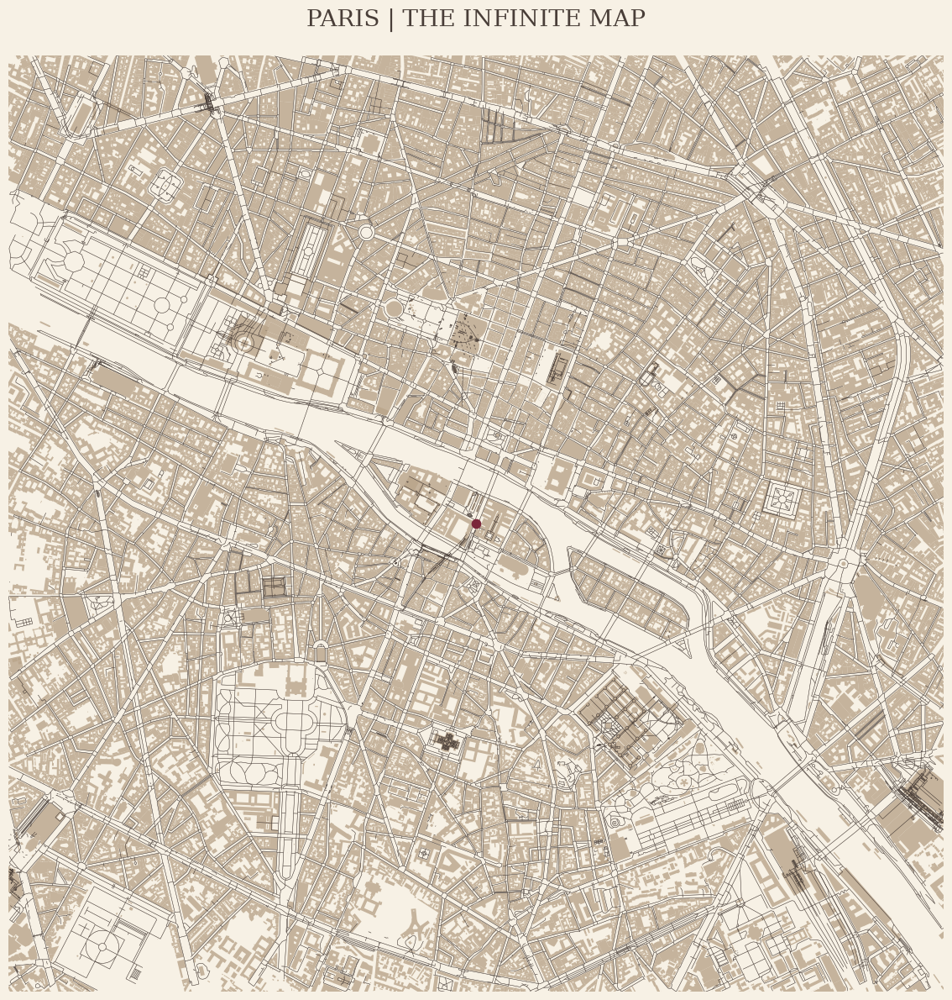

In [7]:

# ============================================================
# 08 | FIRST SPATIAL PREVIEW
# The Infinite Map | Paris, France
# ============================================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

# Parisian-inspired colors
PARCHMENT = "#F7F1E5"
BUILDING = "#B9A48A"
STREET = "#493E38"
ACCENT = "#7A263A"

fig.patch.set_facecolor(PARCHMENT)
ax.set_facecolor(PARCHMENT)

# Building footprints
buildings.plot(
    ax=ax,
    color=BUILDING,
    edgecolor="none",
    alpha=0.8
)

# Street network
street_edges.plot(
    ax=ax,
    color=STREET,
    linewidth=0.35,
    alpha=0.7
)

# Study center
study_center_projected.plot(
    ax=ax,
    color=ACCENT,
    markersize=55,
    zorder=5
)

# Study area extent
xmin, ymin, xmax, ymax = study_boundary.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")

ax.set_title(
    "PARIS | THE INFINITE MAP",
    fontsize=20,
    fontfamily="serif",
    color=STREET,
    pad=25
)

plt.tight_layout()
plt.show()


In [14]:

# ============================================================
# 09 | DOWNLOAD PARIS WATER FEATURES
# The Infinite Map | Paris, France
# ============================================================

import geopandas as gpd
import osmnx as ox

print("Downloading Paris water features...")

# Download water polygons from OpenStreetMap
water_raw = ox.features_from_polygon(
    study_boundary_wgs84.geometry.iloc[0],
    tags={
        "natural": "water",
        "waterway": "riverbank"
    }
)

# Keep polygon and multipolygon geometries
water = water_raw[
    water_raw.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Project to Lambert-93
water = water.to_crs(PARIS_CRS)

# Clip to study area
water = gpd.clip(water, study_boundary)

# Keep only geometry
water = water[["geometry"]].copy()
water = water.reset_index(drop=True)

# Save water layer
water_file = DATA_DIR / "paris_water.gpkg"

water.to_file(
    water_file,
    layer="water",
    driver="GPKG"
)

print("-" * 45)
print(f"Water features: {len(water):,}")
print(f"CRS: {water.crs}")
print(f"Saved to: {water_file.name}")
print("Paris water features downloaded successfully.")


---------------------------------------------
Water features: 220
CRS: EPSG:2154
Saved to: paris_water.gpkg
Paris water features downloaded successfully.


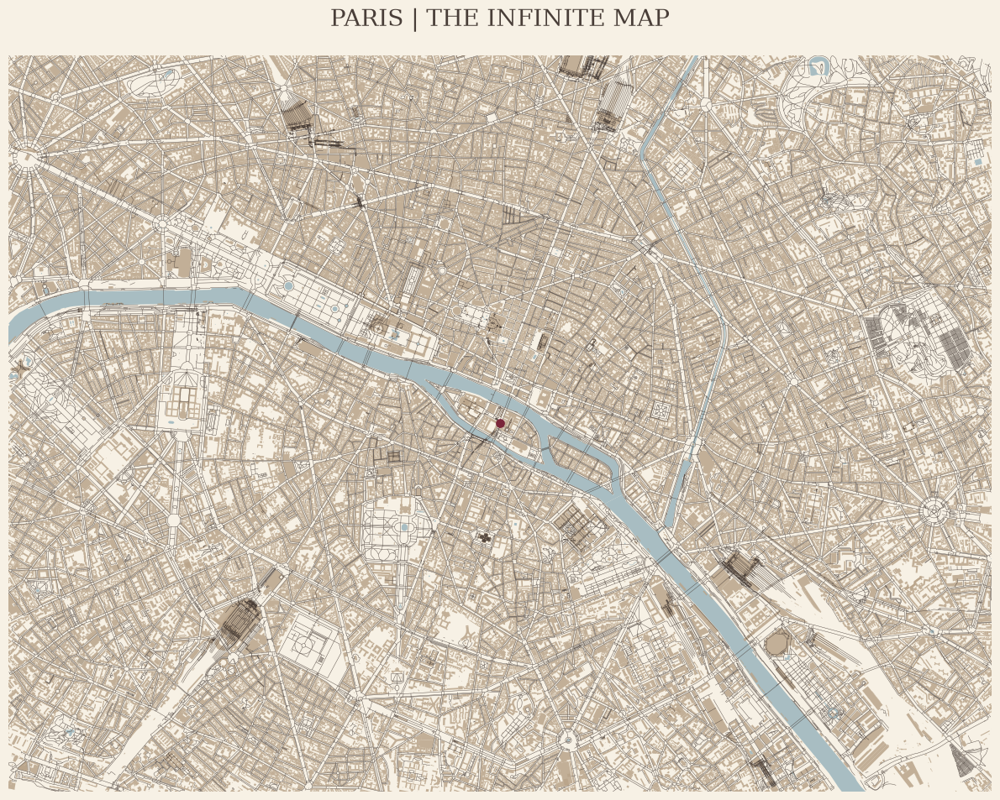

In [15]:

# ============================================================
# 10 | PARIS CARTOGRAPHIC PREVIEW — THE SEINE
# The Infinite Map | Day 14
# ============================================================

import matplotlib.pyplot as plt

# Parisian cartographic palette
PARCHMENT = "#F7F1E5"
BUILDING = "#B9A48A"
STREET = "#493E38"
SEINE = "#A8BDC2"
ACCENT = "#7A263A"

fig, ax = plt.subplots(figsize=(12, 12))

fig.patch.set_facecolor(PARCHMENT)
ax.set_facecolor(PARCHMENT)

# Water — Seine and other mapped water features
water.plot(
    ax=ax,
    color=SEINE,
    edgecolor="none",
    zorder=1
)

# Building footprints
buildings.plot(
    ax=ax,
    color=BUILDING,
    edgecolor="none",
    alpha=0.85,
    zorder=2
)

# Street network
street_edges.plot(
    ax=ax,
    color=STREET,
    linewidth=0.3,
    alpha=0.55,
    zorder=3
)

# Study center
study_center_projected.plot(
    ax=ax,
    color=ACCENT,
    markersize=45,
    zorder=4
)

# Maintain study area extent
xmin, ymin, xmax, ymax = study_boundary.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")

ax.set_title(
    "PARIS | THE INFINITE MAP",
    fontsize=20,
    fontfamily="serif",
    color=STREET,
    pad=25
)

plt.tight_layout()
plt.show()


In [18]:

# ============================================================
# 11 | VERIFY PARIS LANDMARK COVERAGE
# The Infinite Map | Paris, France
# 30DayMapChallenge 2026 — Day 14
# ============================================================

import geopandas as gpd
from shapely.geometry import Point

# ------------------------------------------------------------
# 1 | PARIS LANDMARKS
# Coordinates: longitude, latitude (WGS84)
# ------------------------------------------------------------

landmarks = {
    # Historic landmarks
    "Eiffel Tower": (2.2945, 48.8584),
    "Louvre Museum": (2.3376, 48.8606),
    "Notre-Dame Cathedral": (2.3499, 48.8530),
    "Arc de Triomphe": (2.2950, 48.8738),

    # Luxury fashion landmarks
    "Louis Vuitton Champs-Elysees": (2.3004, 48.8715),
    "Dior 30 Montaigne": (2.3064, 48.8661),

    # Public spaces and gardens
    "Place de la Concorde": (2.3211, 48.8656),
    "Luxor Obelisk": (2.3211, 48.8655),
    "Jardin des Tuileries": (2.3275, 48.8635),
    "Champs-Elysees Avenue": (2.3075, 48.8693),
}

# ------------------------------------------------------------
# 2 | CREATE GEOGRAPHIC POINTS
# ------------------------------------------------------------

landmark_points = gpd.GeoDataFrame(
    {"name": list(landmarks.keys())},
    geometry=[
        Point(lon, lat)
        for lon, lat in landmarks.values()
    ],
    crs=WGS84
).to_crs(PARIS_CRS)

# ------------------------------------------------------------
# 3 | VERIFY STUDY AREA COVERAGE
# ------------------------------------------------------------

boundary_geom = study_boundary.geometry.iloc[0]

print("PARIS LANDMARK COVERAGE")
print("=" * 55)

inside_count = 0

for _, landmark in landmark_points.iterrows():

    inside = boundary_geom.covers(landmark.geometry)

    if inside:
        inside_count += 1

    status = "INSIDE" if inside else "OUTSIDE"

    print(f"{landmark['name']}: {status}")

# ------------------------------------------------------------
# 4 | SUMMARY
# ------------------------------------------------------------

print("=" * 55)
print(f"Landmarks inside study area: {inside_count}/{len(landmark_points)}")

if inside_count == len(landmark_points):
    print("All Paris landmarks are within the study area.")
else:
    print("WARNING: Some landmarks are outside the study area.")

print("-" * 55)
print("Study area:", f"{study_boundary.geometry.area.iloc[0] / 1e6:.2f} km²")
print("Coordinate system:", PARIS_CRS)


PARIS LANDMARK COVERAGE
Eiffel Tower: INSIDE
Louvre Museum: INSIDE
Notre-Dame Cathedral: INSIDE
Arc de Triomphe: INSIDE
Louis Vuitton Champs-Elysees: INSIDE
Dior 30 Montaigne: INSIDE
Place de la Concorde: INSIDE
Luxor Obelisk: INSIDE
Jardin des Tuileries: INSIDE
Champs-Elysees Avenue: INSIDE
Landmarks inside study area: 10/10
All Paris landmarks are within the study area.
-------------------------------------------------------
Study area: 48.00 km²
Coordinate system: EPSG:2154


In [19]:

# ============================================================
# 12 | DOWNLOAD PARIS PARKS AND GREEN SPACES
# The Infinite Map | Paris, France
# 30DayMapChallenge 2026 — Day 14
# ============================================================

import geopandas as gpd
import osmnx as ox

print("Downloading Paris parks and green spaces...")

# Download mapped parks, gardens, and grass areas
green_raw = ox.features_from_polygon(
    study_boundary_wgs84.geometry.iloc[0],
    tags={
        "leisure": ["park", "garden"],
        "landuse": ["grass", "recreation_ground"],
        "natural": ["grassland", "wood"]
    }
)

# Keep area geometries
green_spaces = green_raw[
    green_raw.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

# Project to French CRS
green_spaces = green_spaces.to_crs(PARIS_CRS)

# Clip to expanded study boundary
green_spaces = gpd.clip(
    green_spaces,
    study_boundary
)

# Keep geometry and create identifiers
green_spaces = green_spaces[["geometry"]].copy()
green_spaces = green_spaces.reset_index(drop=True)
green_spaces["green_id"] = range(
    1, len(green_spaces) + 1
)

# Save as GeoPackage
green_file = DATA_DIR / "paris_green_spaces.gpkg"

green_spaces.to_file(
    green_file,
    layer="green_spaces",
    driver="GPKG"
)

# Calculate mapped area
green_area_km2 = (
    green_spaces.geometry.area.sum() / 1e6
)

print("-" * 50)
print(f"Green space polygons: {len(green_spaces):,}")
print(f"Total polygon area: {green_area_km2:.2f} km²")
print(f"CRS: {green_spaces.crs}")
print(f"Saved to: {green_file.name}")
print("Paris green spaces downloaded successfully.")


--------------------------------------------------
Green space polygons: 3,468
Total polygon area: 4.59 km²
CRS: EPSG:2154
Saved to: paris_green_spaces.gpkg
Paris green spaces downloaded successfully.


In [20]:

# ============================================================
# 13 | DOWNLOAD PARIS INDIVIDUAL TREES
# The Infinite Map | Paris, France
# 30DayMapChallenge 2026 — Day 14
# ============================================================

import geopandas as gpd
import osmnx as ox

print("Downloading individual trees in Paris...")

# Download mapped trees from OpenStreetMap
trees_raw = ox.features_from_polygon(
    study_boundary_wgs84.geometry.iloc[0],
    tags={"natural": "tree"}
)

# Keep individual tree points only
trees = trees_raw[
    trees_raw.geometry.geom_type == "Point"
].copy()

# Project to Lambert-93
trees = trees.to_crs(PARIS_CRS)

# Keep only points inside study area
trees = gpd.clip(trees, study_boundary)

# Assign unique identifiers
trees = trees[["geometry"]].copy()
trees = trees.reset_index(drop=True)
trees["tree_id"] = range(1, len(trees) + 1)

# Save as GeoPackage
tree_file = DATA_DIR / "paris_trees.gpkg"

if not trees.empty:
    trees.to_file(
        tree_file,
        layer="trees",
        driver="GPKG"
    )

print("-" * 50)
print(f"Individual trees: {len(trees):,}")
print(f"CRS: {trees.crs}")

if not trees.empty:
    print(f"Saved to: {tree_file.name}")
else:
    print("No individual tree points found in OpenStreetMap.")

print("-" * 50)
print("Tree data processing completed.")


--------------------------------------------------
Individual trees: 77,483
CRS: EPSG:2154
Saved to: paris_trees.gpkg
--------------------------------------------------
Tree data processing completed.


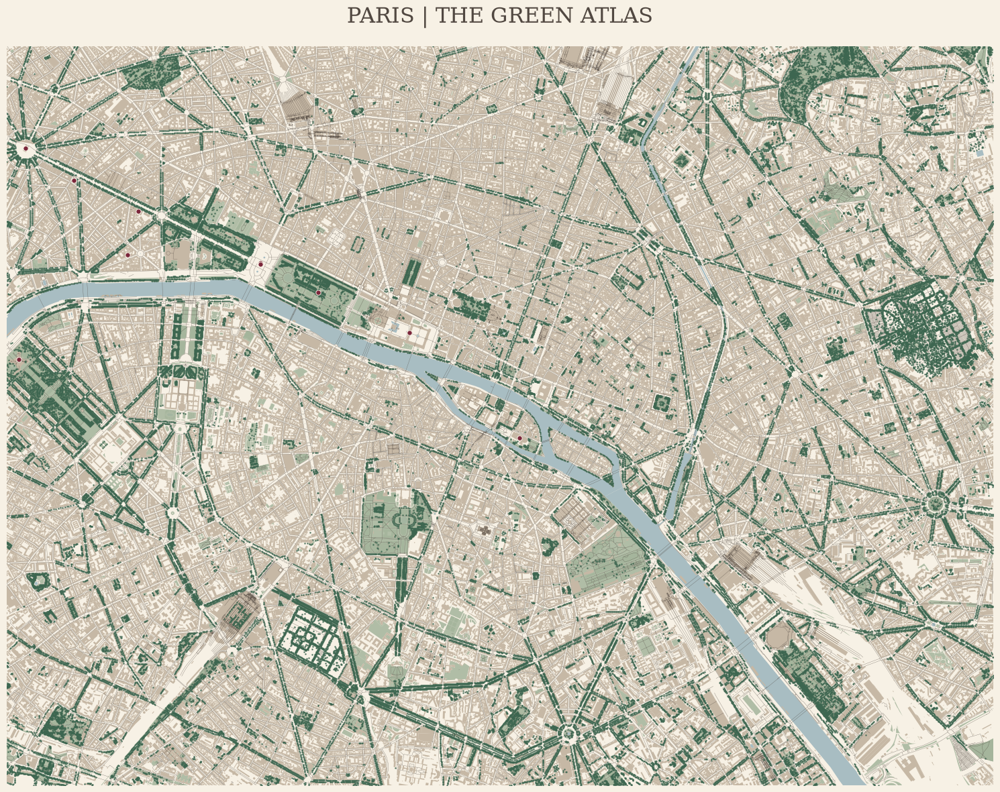

In [21]:

# ============================================================
# 14 | PARIS GREEN ATLAS — SPATIAL PREVIEW
# The Infinite Map | Paris, France
# 30DayMapChallenge 2026 — Day 14
# ============================================================

import matplotlib.pyplot as plt

# Parisian cartographic palette
PARCHMENT = "#F7F1E5"
BUILDING = "#C6B8A5"
STREET = "#514841"
SEINE = "#A8BDC2"
GARDEN = "#A4B49B"
TREE = "#3D6650"
ACCENT = "#7A263A"

fig, ax = plt.subplots(figsize=(15, 12))

fig.patch.set_facecolor(PARCHMENT)
ax.set_facecolor(PARCHMENT)

# 1 | Water
water.plot(
    ax=ax,
    color=SEINE,
    edgecolor="none",
    zorder=1
)

# 2 | Parks and gardens
green_spaces.plot(
    ax=ax,
    color=GARDEN,
    edgecolor="none",
    alpha=0.85,
    zorder=2
)

# 3 | Buildings
buildings.plot(
    ax=ax,
    color=BUILDING,
    edgecolor="none",
    zorder=3
)

# 4 | Streets
street_edges.plot(
    ax=ax,
    color=STREET,
    linewidth=0.22,
    alpha=0.45,
    zorder=4
)

# 5 | Individual trees
trees.plot(
    ax=ax,
    color=TREE,
    markersize=0.65,
    alpha=0.8,
    zorder=5
)

# 6 | Landmark locations
landmark_points.plot(
    ax=ax,
    color=ACCENT,
    markersize=28,
    edgecolor=PARCHMENT,
    linewidth=0.7,
    zorder=6
)

# Study area extent
xmin, ymin, xmax, ymax = study_boundary.total_bounds

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")

ax.set_title(
    "PARIS | THE GREEN ATLAS",
    fontsize=23,
    fontfamily="serif",
    color=STREET,
    pad=25
)

plt.tight_layout()
plt.show()


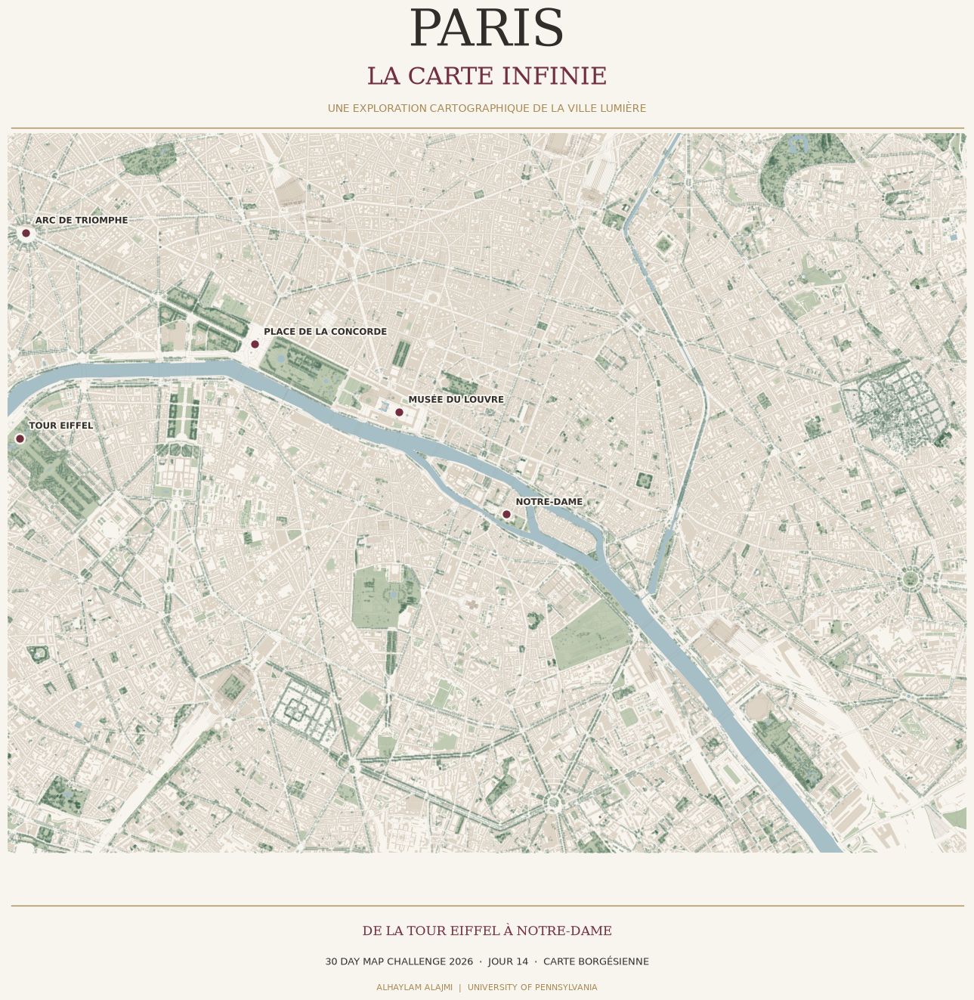

In [22]:

# ============================================================
# 15 | LA CARTE INFINIE — PARIS EDITORIAL ATLAS
# 30DayMapChallenge 2026 | Day 14
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Rectangle
from matplotlib import font_manager
import geopandas as gpd

# ------------------------------------------------------------
# 1 | PARISIAN LUXURY PALETTE
# ------------------------------------------------------------

IVORY = "#F8F5EE"
STONE = "#DDD4C6"
STREET = "#9C9388"
SEINE = "#A6BEC5"
GARDEN = "#B6C4AA"
TREE = "#486D58"
BURGUNDY = "#722F40"
GOLD = "#A88A54"
INK = "#302D2B"

# ------------------------------------------------------------
# 2 | CANVAS
# ------------------------------------------------------------

fig = plt.figure(figsize=(18, 14), facecolor=IVORY)

ax = fig.add_axes([0.055, 0.17, 0.89, 0.68])
ax.set_facecolor(IVORY)

# ------------------------------------------------------------
# 3 | MAP LAYERS
# ------------------------------------------------------------

# Buildings
buildings.plot(
    ax=ax,
    color=STONE,
    edgecolor="none",
    zorder=1
)

# Gardens and green spaces
green_spaces.plot(
    ax=ax,
    color=GARDEN,
    edgecolor="none",
    alpha=0.85,
    zorder=2
)

# Seine and waterways
water.plot(
    ax=ax,
    color=SEINE,
    edgecolor="none",
    zorder=3
)

# Streets — subtle, not dominant
street_edges.plot(
    ax=ax,
    color=STREET,
    linewidth=0.12,
    alpha=0.32,
    zorder=4
)

# Individual trees — understated
trees.plot(
    ax=ax,
    color=TREE,
    markersize=0.12,
    alpha=0.42,
    zorder=5
)

# ------------------------------------------------------------
# 4 | FEATURED LANDMARKS
# ------------------------------------------------------------

featured = {
    "TOUR EIFFEL": "Eiffel Tower",
    "ARC DE TRIOMPHE": "Arc de Triomphe",
    "MUSÉE DU LOUVRE": "Louvre Museum",
    "NOTRE-DAME": "Notre-Dame Cathedral",
    "PLACE DE LA CONCORDE": "Place de la Concorde",
}

for french_name, english_name in featured.items():

    point = landmark_points.loc[
        landmark_points["name"] == english_name
    ].geometry.iloc[0]

    ax.scatter(
        point.x,
        point.y,
        s=85,
        facecolor=BURGUNDY,
        edgecolor=IVORY,
        linewidth=1.8,
        zorder=10
    )

    ax.annotate(
        french_name,
        xy=(point.x, point.y),
        xytext=(9, 9),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
        color=INK,
        zorder=11,
        path_effects=[
            pe.withStroke(linewidth=3, foreground=IVORY)
        ]
    )

# ------------------------------------------------------------
# 5 | MAP EXTENT
# ------------------------------------------------------------

xmin, ymin, xmax, ymax = study_boundary.total_bounds

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")

# ------------------------------------------------------------
# 6 | EDITORIAL TYPOGRAPHY
# ------------------------------------------------------------

fig.text(
    0.5, 0.945,
    "PARIS",
    ha="center",
    va="center",
    fontsize=48,
    fontfamily="serif",
    color=INK
)

fig.text(
    0.5, 0.902,
    "LA CARTE INFINIE",
    ha="center",
    va="center",
    fontsize=23,
    fontfamily="serif",
    color=BURGUNDY
)

fig.text(
    0.5, 0.870,
    "UNE EXPLORATION CARTOGRAPHIQUE DE LA VILLE LUMIÈRE",
    ha="center",
    fontsize=10,
    color=GOLD
)

# ------------------------------------------------------------
# 7 | DECORATIVE RULES
# ------------------------------------------------------------

fig.add_artist(
    plt.Line2D(
        [0.15, 0.85],
        [0.855, 0.855],
        transform=fig.transFigure,
        color=GOLD,
        linewidth=1
    )
)

fig.add_artist(
    plt.Line2D(
        [0.15, 0.85],
        [0.12, 0.12],
        transform=fig.transFigure,
        color=GOLD,
        linewidth=1
    )
)

# ------------------------------------------------------------
# 8 | FOOTER
# ------------------------------------------------------------

fig.text(
    0.5, 0.092,
    "DE LA TOUR EIFFEL À NOTRE-DAME",
    ha="center",
    fontsize=12,
    fontfamily="serif",
    color=BURGUNDY
)

fig.text(
    0.5, 0.064,
    "30 DAY MAP CHALLENGE 2026  ·  JOUR 14  ·  CARTE BORGÉSIENNE",
    ha="center",
    fontsize=9,
    color=INK
)

fig.text(
    0.5, 0.040,
    "ALHAYLAM ALAJMI  |  UNIVERSITY OF PENNSYLVANIA",
    ha="center",
    fontsize=8,
    color=GOLD
)

# ------------------------------------------------------------
# 9 | PREVIEW
# ------------------------------------------------------------

plt.show()


In [24]:

# ============================================================
# 16 | LA CARTE INFINIE — INTERACTIVE PARIS
# 30DayMapChallenge 2026 | Day 14
# ============================================================

import folium
import geopandas as gpd
from branca.element import Element

# ------------------------------------------------------------
# 1 | PREPARE GEOGRAPHIC DATA
# ------------------------------------------------------------

water_web = water.to_crs("EPSG:4326")
green_web = green_spaces.to_crs("EPSG:4326")
buildings_web = buildings.to_crs("EPSG:4326")
landmarks_web = landmark_points.to_crs("EPSG:4326")

# ------------------------------------------------------------
# 2 | CREATE INTERACTIVE MAP
# ------------------------------------------------------------

paris_map = folium.Map(
    location=[48.862, 2.324],
    zoom_start=13,
    tiles=None,
    control_scale=True,
    prefer_canvas=True,
    width="100%",
    height=650
)

# OpenStreetMap background — no API key required
folium.TileLayer(
    tiles="OpenStreetMap",
    name="Paris | Base Map",
    control=True
).add_to(paris_map)

# ------------------------------------------------------------
# 3 | SEINE RIVER AND WATER FEATURES
# ------------------------------------------------------------

folium.GeoJson(
    water_web[["geometry"]],
    name="La Seine",
    style_function=lambda feature: {
        "fillColor": "#A6BEC5",
        "color": "#A6BEC5",
        "weight": 0,
        "fillOpacity": 0.9
    },
    zoom_on_click=False
).add_to(paris_map)

# ------------------------------------------------------------
# 4 | PARKS AND GARDENS
# ------------------------------------------------------------

folium.GeoJson(
    green_web[["geometry"]],
    name="Jardins de Paris",
    style_function=lambda feature: {
        "fillColor": "#A4B49B",
        "color": "#A4B49B",
        "weight": 0,
        "fillOpacity": 0.65
    }
).add_to(paris_map)

# ------------------------------------------------------------
# 5 | PARIS BUILDING FOOTPRINTS
# ------------------------------------------------------------

folium.GeoJson(
    buildings_web[["geometry"]],
    name="Architecture de Paris",
    style_function=lambda feature: {
        "fillColor": "#C9BBA7",
        "color": "#998C7D",
        "weight": 0.3,
        "fillOpacity": 0.65
    },
    show=False
).add_to(paris_map)

# ------------------------------------------------------------
# 6 | PARIS LANDMARKS
# ------------------------------------------------------------

for _, landmark in landmarks_web.iterrows():

    folium.CircleMarker(
        location=[
            landmark.geometry.y,
            landmark.geometry.x
        ],
        radius=6,
        color="#F8F5EE",
        weight=2,
        fill=True,
        fill_color="#722F40",
        fill_opacity=1,
        tooltip=landmark["name"],
        popup=folium.Popup(
            f"<b>{landmark['name']}</b>",
            max_width=250
        )
    ).add_to(paris_map)

# ------------------------------------------------------------
# 7 | FRENCH EDITORIAL TITLE
# ------------------------------------------------------------

title_html = """
<div style="
    position: fixed;
    top: 18px;
    left: 50%;
    transform: translateX(-50%);
    z-index: 9999;
    background: rgba(248,245,238,0.96);
    padding: 14px 30px;
    border: 1px solid #A88A54;
    box-shadow: 0 4px 18px rgba(0,0,0,0.12);
    text-align: center;
    min-width: 260px;
">
    <div style="
        font-family: Georgia,serif;
        font-size: 25px;
        letter-spacing: 3px;
        color: #302D2B;
    ">
        PARIS
    </div>

    <div style="
        font-family: Georgia,serif;
        font-size: 13px;
        letter-spacing: 2px;
        color: #722F40;
    ">
        LA CARTE INFINIE
    </div>
</div>
"""

paris_map.get_root().html.add_child(
    Element(title_html)
)

# ------------------------------------------------------------
# 8 | LAYER CONTROL
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(paris_map)

# ------------------------------------------------------------
# 9 | SAVE INTERACTIVE HTML
# ------------------------------------------------------------

interactive_file = EXPORTS_DIR / "Paris_La_Carte_Infinie.html"

paris_map.save(str(interactive_file))

print("INTERACTIVE PARIS MAP")
print("-" * 45)
print(f"Saved: {interactive_file.name}")
print(f"Landmarks: {len(landmarks_web)}")
print("Interactive map created successfully.")

# ------------------------------------------------------------
# 10 | DISPLAY MAP
# ------------------------------------------------------------

paris_map


INTERACTIVE PARIS MAP
---------------------------------------------
Saved: Paris_La_Carte_Infinie.html
Landmarks: 10
Interactive map created successfully.


In [25]:

# ============================================================
# 17 | CHECK 3D MAP REQUIREMENTS
# The Infinite Map | Paris, France
# ============================================================

import importlib.util

packages = {
    "GeoPandas": "geopandas",
    "Shapely": "shapely",
    "PyProj": "pyproj",
    "Requests": "requests",
    "Folium": "folium",
}

print("3D MAP REQUIREMENTS")
print("-" * 45)

for name, module in packages.items():
    status = "READY" if importlib.util.find_spec(module) else "MISSING"
    print(f"{name}: {status}")

print("-" * 45)
print("Python dependency check completed.")


3D MAP REQUIREMENTS
---------------------------------------------
GeoPandas: READY
Shapely: READY
PyProj: READY
Requests: READY
Folium: READY
---------------------------------------------
Python dependency check completed.


In [26]:

# ============================================================
# 18 | PREPARE PARIS BUILDINGS FOR 3D
# The Infinite Map | Paris, France
# ============================================================

import geopandas as gpd
import numpy as np

print("Preparing Paris buildings for 3D visualization...")

# Copy existing building footprints
buildings_3d = buildings.copy()

# Remove empty or invalid geometries
buildings_3d = buildings_3d[
    buildings_3d.geometry.notna()
    & ~buildings_3d.geometry.is_empty
    & buildings_3d.geometry.is_valid
].copy()

# Temporary visualization heights (NOT measured heights)
# Use a constant height to avoid inventing building-specific data
buildings_3d["height_m"] = 15.0

# Convert to geographic coordinates for web mapping
buildings_3d_web = buildings_3d.to_crs("EPSG:4326")

# Keep only essential attributes
buildings_3d_web = buildings_3d_web[
    ["building_id", "height_m", "geometry"]
].copy()

# Save GeoJSON for MapLibre
buildings_3d_file = DATA_DIR / "paris_buildings_3d.geojson"

buildings_3d_web.to_file(
    buildings_3d_file,
    driver="GeoJSON"
)

print("-" * 50)
print(f"Buildings prepared: {len(buildings_3d_web):,}")
print("Temporary height: 15 m")
print(f"Saved: {buildings_3d_file.name}")
print("-" * 50)
print("3D building data prepared successfully.")


Preparing Paris buildings for 3D visualization...
--------------------------------------------------
Buildings prepared: 62,193
Temporary height: 15 m
Saved: paris_buildings_3d.geojson
--------------------------------------------------
3D building data prepared successfully.


In [27]:

# ============================================================
# 19 | CHECK 3D BUILDING DATA SIZE
# The Infinite Map | Paris, France
# ============================================================

file_size_mb = buildings_3d_file.stat().st_size / (1024 ** 2)

print("PARIS 3D DATA CHECK")
print("-" * 45)
print(f"Buildings: {len(buildings_3d_web):,}")
print(f"GeoJSON size: {file_size_mb:.2f} MB")
print("-" * 45)

if file_size_mb > 20:
    print("Large file: optimization recommended before web mapping.")
else:
    print("File size is reasonable for initial testing.")


PARIS 3D DATA CHECK
---------------------------------------------
Buildings: 62,193
GeoJSON size: 33.89 MB
---------------------------------------------
Large file: optimization recommended before web mapping.


In [28]:

# ============================================================
# 20 | OPTIMIZE PARIS 3D BUILDING GEOMETRIES
# The Infinite Map | Paris, France
# ============================================================

import geopandas as gpd

print("Optimizing Paris building geometries...")

# Work in metric coordinates for accurate simplification
buildings_optimized = buildings_3d_web.to_crs(PARIS_CRS).copy()

# Simplify geometry with 0.5-meter tolerance
# Preserve topology to avoid invalid polygons
buildings_optimized["geometry"] = (
    buildings_optimized.geometry.simplify(
        tolerance=0.5,
        preserve_topology=True
    )
)

# Remove empty or invalid geometries
buildings_optimized = buildings_optimized[
    buildings_optimized.geometry.notna()
    & ~buildings_optimized.geometry.is_empty
    & buildings_optimized.geometry.is_valid
].copy()

# Convert back to WGS84
buildings_optimized = buildings_optimized.to_crs(WGS84)

# Save optimized GeoJSON
optimized_file = DATA_DIR / "paris_buildings_3d_optimized.geojson"

buildings_optimized.to_file(
    optimized_file,
    driver="GeoJSON"
)

# Compare sizes
original_mb = buildings_3d_file.stat().st_size / (1024 ** 2)
optimized_mb = optimized_file.stat().st_size / (1024 ** 2)

reduction = (1 - optimized_mb / original_mb) * 100

print("-" * 50)
print(f"Buildings retained: {len(buildings_optimized):,}")
print(f"Original size: {original_mb:.2f} MB")
print(f"Optimized size: {optimized_mb:.2f} MB")
print(f"Size reduction: {reduction:.1f}%")
print(f"Saved: {optimized_file.name}")
print("-" * 50)
print("Building geometry optimization completed.")


Optimizing Paris building geometries...
--------------------------------------------------
Buildings retained: 62,193
Original size: 33.89 MB
Optimized size: 27.16 MB
Size reduction: 19.8%
Saved: paris_buildings_3d_optimized.geojson
--------------------------------------------------
Building geometry optimization completed.


In [29]:

# ============================================================
# 21 | CREATE LIGHTWEIGHT 3D BUILDING DATA
# The Infinite Map | Paris, France
# ============================================================

import json
import gzip

print("Creating lightweight 3D building data...")

# Keep optimized geometries and essential attributes
light_buildings = buildings_optimized[
    ["building_id", "height_m", "geometry"]
].copy()

# Generate compact GeoJSON
geojson_data = json.loads(light_buildings.to_json())

# Save compact JSON without unnecessary whitespace
compact_file = DATA_DIR / "paris_buildings_3d_compact.geojson"

with open(compact_file, "w", encoding="utf-8") as f:
    json.dump(
        geojson_data,
        f,
        ensure_ascii=False,
        separators=(",", ":")
    )

# Also create compressed version
gzip_file = DATA_DIR / "paris_buildings_3d_compact.geojson.gz"

with gzip.open(gzip_file, "wt", encoding="utf-8") as f:
    json.dump(
        geojson_data,
        f,
        ensure_ascii=False,
        separators=(",", ":")
    )

# Compare sizes
compact_mb = compact_file.stat().st_size / (1024 ** 2)
gzip_mb = gzip_file.stat().st_size / (1024 ** 2)

print("-" * 50)
print(f"Buildings: {len(light_buildings):,}")
print(f"Compact GeoJSON: {compact_mb:.2f} MB")
print(f"GZIP compressed: {gzip_mb:.2f} MB")
print("-" * 50)
print("Lightweight building data created successfully.")


Creating lightweight 3D building data...
--------------------------------------------------
Buildings: 62,193
Compact GeoJSON: 29.56 MB
GZIP compressed: 5.00 MB
--------------------------------------------------
Lightweight building data created successfully.


In [32]:

# ============================================================
# 22 | PARIS — INTERACTIVE 3D MAP (OPENFREEMAP)
# The Infinite Map | Paris, France
# ============================================================

import json
from pathlib import Path

# Load optimized building data
with open(compact_file, "r", encoding="utf-8") as f:
    building_geojson = json.load(f)

# Keep only fields needed for 3D rendering
for feature in building_geojson["features"]:
    feature["properties"] = {
        "height_m": feature["properties"].get("height_m", 15)
    }

# Embed GeoJSON to avoid local file restrictions
buildings_json = json.dumps(
    building_geojson,
    ensure_ascii=False,
    separators=(",", ":")
).replace("</", "<\\/")

html = r"""
<!DOCTYPE html>
<html lang="fr">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Paris — La Carte Infinie</title>

<link href="https://unpkg.com/maplibre-gl@5.6.2/dist/maplibre-gl.css" rel="stylesheet">
<script src="https://unpkg.com/maplibre-gl@5.6.2/dist/maplibre-gl.js"></script>

<style>
* { box-sizing: border-box; }

body {
    margin: 0;
    background: #F8F5EE;
    font-family: Georgia, serif;
}

#map {
    position: absolute;
    inset: 0;
}

.header {
    position: absolute;
    top: 25px;
    left: 25px;
    z-index: 2;
    background: rgba(248,245,238,0.95);
    padding: 22px 28px;
    border: 1px solid #A88A54;
    max-width: 340px;
    box-shadow: 0 8px 25px #00000015;
}

.kicker {
    font: 11px Arial, sans-serif;
    letter-spacing: 3px;
    color: #722F40;
}

h1 {
    font-size: 29px;
    font-weight: normal;
    margin: 10px 0;
    color: #302D2B;
}

.subtitle {
    font: 12px Arial, sans-serif;
    color: #666;
    line-height: 1.6;
}

.footer {
    position: absolute;
    bottom: 20px;
    left: 25px;
    z-index: 2;
    background: rgba(248,245,238,0.95);
    padding: 10px 15px;
    font: 11px Arial, sans-serif;
    color: #302D2B;
    border: 1px solid #DDD4C6;
}

@media (max-width: 600px) {
    .header {
        top: 12px;
        left: 12px;
        padding: 14px 18px;
        max-width: 260px;
    }
    h1 { font-size: 22px; }
}
</style>
</head>

<body>

<div id="map"></div>

<div class="header">
    <div class="kicker">ATLAS DE PARIS · 2026</div>
    <h1>LA CARTE INFINIE</h1>
    <div class="subtitle">
        Une ville, mille échelles.<br>
        Paris en trois dimensions.
    </div>
</div>

<div class="footer">
    DAY 14 · BORGESIAN MAP · 3D EXPERIMENT
</div>

<script>

const buildings = __BUILDINGS__;

const map = new maplibregl.Map({
    container: 'map',

    // Verified OpenFreeMap vector style
    style: 'https://tiles.openfreemap.org/styles/liberty',

    center: [2.327, 48.861],
    zoom: 14.2,
    pitch: 58,
    bearing: -25,
    antialias: true
});

map.addControl(
    new maplibregl.NavigationControl(),
    'top-right'
);

map.on('load', () => {

    map.addSource('paris-buildings', {
        type: 'geojson',
        data: buildings
    });

    map.addLayer({
        id: 'paris-buildings-3d',
        type: 'fill-extrusion',
        source: 'paris-buildings',
        minzoom: 13,

        paint: {
            'fill-extrusion-color': '#C8B7A1',

            'fill-extrusion-height': [
                'interpolate',
                ['linear'],
                ['zoom'],
                13, 0,
                15, ['get', 'height_m']
            ],

            'fill-extrusion-base': 0,
            'fill-extrusion-opacity': 0.83
        }
    });

});

</script>
</body>
</html>
"""

html = html.replace("__BUILDINGS__", buildings_json)

output_3d = EXPORTS_DIR / "Paris_La_Carte_Infinie_3D.html"

output_3d.write_text(html, encoding="utf-8")

print("PARIS 3D MAP — OPENFREEMAP")
print("-" * 50)
print(f"Saved: {output_3d}")
print(f"Buildings: {len(building_geojson['features']):,}")
print(f"HTML size: {output_3d.stat().st_size / 1024**2:.2f} MB")
print("Basemap: OpenFreeMap Liberty")
print("API key: NOT REQUIRED")
print("3D buildings: ENABLED")
print("-" * 50)
print("Open the updated HTML file in your browser.")


PARIS 3D MAP — OPENFREEMAP
--------------------------------------------------
Saved: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\exports\Paris_La_Carte_Infinie_3D.html
Buildings: 62,193
HTML size: 28.38 MB
Basemap: OpenFreeMap Liberty
API key: NOT REQUIRED
3D buildings: ENABLED
--------------------------------------------------
Open the updated HTML file in your browser.


In [33]:

# ============================================================
# 23 | PARIS — BORGESIAN DETAIL LAYER
# The Infinite Map | Day 14
# ============================================================

import json

# Read the existing tree dataset
trees_detail = gpd.read_file(DATA_DIR / "paris_trees.gpkg")

# Ensure WGS84 coordinates
trees_detail = trees_detail.to_crs("EPSG:4326")

# Keep point geometries only
trees_detail = trees_detail[
    trees_detail.geometry.notna()
    & ~trees_detail.geometry.is_empty
    & trees_detail.geom_type.isin(["Point", "MultiPoint"])
].copy()

# Keep essential spatial information
trees_detail = trees_detail[["geometry"]]

trees_json = trees_detail.to_json()

# Embed tree data in existing HTML
tree_script = """
<script>
const parisTrees = __TREES__;

map.on('load', () => {
    map.addSource('paris-trees', {
        type: 'geojson',
        data: parisTrees
    });

    map.addLayer({
        id: 'paris-individual-trees',
        type: 'circle',
        source: 'paris-trees',
        minzoom: 16,
        paint: {
            'circle-radius': [
                'interpolate', ['linear'], ['zoom'],
                16, 1.5,
                19, 5
            ],
            'circle-color': '#486D58',
            'circle-opacity': 0.85,
            'circle-stroke-color': '#F8F5EE',
            'circle-stroke-width': 0.5
        }
    });
});
</script>
"""

tree_script = tree_script.replace(
    "__TREES__",
    trees_json.replace("</", "<\\/")
)

# Read the existing working 3D HTML
existing_html = output_3d.read_text(encoding="utf-8")

# Insert the tree layer before the closing body tag
updated_html = existing_html.replace(
    "</body>",
    tree_script + "\n</body>"
)

# Save a new version without changing the working map
borgesian_file = EXPORTS_DIR / "Paris_La_Carte_Infinie_Borgesian.html"

borgesian_file.write_text(
    updated_html,
    encoding="utf-8"
)

print("BORGESIAN PARIS MAP CREATED")
print("-" * 50)
print(f"Trees added: {len(trees_detail):,}")
print("Tree visibility: Zoom 16+")
print(f"Saved: {borgesian_file.name}")
print("-" * 50)


BORGESIAN PARIS MAP CREATED
--------------------------------------------------
Trees added: 77,483
Tree visibility: Zoom 16+
Saved: Paris_La_Carte_Infinie_Borgesian.html
--------------------------------------------------


In [34]:

# ============================================================
# 25 | LA CARTE INFINIE — COMPLETE BORGESIAN PARIS ATLAS
# Day 14 | 30DayMapChallenge 2026
# ============================================================

from pathlib import Path
import json
import html as html_lib
import geopandas as gpd
import pandas as pd

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

CODE_DIR = Path.cwd().resolve()
PROJECT_DIR = CODE_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
EXPORTS_DIR = PROJECT_DIR / "exports"

EXPORTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = EXPORTS_DIR / "Paris_La_Carte_Infinie_FINAL.html"

WGS84 = "EPSG:4326"
PARIS_CRS = "EPSG:2154"

print("BUILDING THE INFINITE MAP — PARIS")
print("-" * 55)

# ------------------------------------------------------------
# 2. LOAD SPATIAL DATA
# ------------------------------------------------------------

buildings_file = DATA_DIR / "paris_buildings_3d_optimized.geojson"
trees_file = DATA_DIR / "paris_trees.gpkg"
water_file = DATA_DIR / "paris_water.gpkg"
parks_file = DATA_DIR / "paris_green_spaces.gpkg"

required_files = [
    buildings_file,
    trees_file,
    water_file,
    parks_file
]

missing = [str(p) for p in required_files if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Missing required data files:\n" + "\n".join(missing)
    )

buildings = gpd.read_file(buildings_file).to_crs(WGS84)
trees = gpd.read_file(trees_file).to_crs(WGS84)
water = gpd.read_file(water_file).to_crs(WGS84)
parks = gpd.read_file(parks_file).to_crs(WGS84)

# ------------------------------------------------------------
# 3. PREPARE GEOJSON
# ------------------------------------------------------------

def clean_geodataframe(gdf, geometry_types):
    result = gdf[
        gdf.geometry.notna()
        & ~gdf.geometry.is_empty
        & gdf.geom_type.isin(geometry_types)
    ].copy()

    return result[["geometry"]].reset_index(drop=True)


buildings = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
    & buildings.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

if "height_m" not in buildings.columns:
    buildings["height_m"] = 15.0

buildings["height_m"] = (
    pd.to_numeric(buildings["height_m"], errors="coerce")
    .fillna(15.0)
    .clip(lower=1, upper=300)
)

buildings = buildings[["height_m", "geometry"]]

trees = clean_geodataframe(
    trees,
    ["Point", "MultiPoint"]
)

water = clean_geodataframe(
    water,
    ["Polygon", "MultiPolygon"]
)

parks = clean_geodataframe(
    parks,
    ["Polygon", "MultiPolygon"]
)

def compact_geojson(gdf):
    return json.dumps(
        json.loads(gdf.to_json()),
        ensure_ascii=False,
        separators=(",", ":")
    ).replace("</", "<\\/")


buildings_json = compact_geojson(buildings)
trees_json = compact_geojson(trees)
water_json = compact_geojson(water)
parks_json = compact_geojson(parks)

print(f"Buildings: {len(buildings):,}")
print(f"Trees: {len(trees):,}")
print(f"Water features: {len(water):,}")
print(f"Green spaces: {len(parks):,}")

# ------------------------------------------------------------
# 4. PARIS LANDMARKS
# Coordinates are approximate reference points
# ------------------------------------------------------------

landmarks_data = [
    {
        "name": "Tour Eiffel",
        "english": "Eiffel Tower",
        "category": "MONUMENT",
        "coordinates": [2.2945, 48.8584],
        "description": "La silhouette emblématique de Paris."
    },
    {
        "name": "Musée du Louvre",
        "english": "Louvre Museum",
        "category": "CULTURE",
        "coordinates": [2.3376, 48.8606],
        "description": "Un palais, un musée, une histoire."
    },
    {
        "name": "Notre-Dame de Paris",
        "english": "Notre-Dame Cathedral",
        "category": "HERITAGE",
        "coordinates": [2.3499, 48.8530],
        "description": "Le cœur historique de la capitale."
    },
    {
        "name": "Arc de Triomphe",
        "english": "Arc de Triomphe",
        "category": "MONUMENT",
        "coordinates": [2.2950, 48.8738],
        "description": "Au sommet des Champs-Élysées."
    },
    {
        "name": "Louis Vuitton Champs-Élysées",
        "english": "Louis Vuitton",
        "category": "FASHION",
        "coordinates": [2.3004, 48.8715],
        "description": "La haute tradition de la mode parisienne."
    },
    {
        "name": "Dior — 30 Montaigne",
        "english": "Dior",
        "category": "FASHION",
        "coordinates": [2.3064, 48.8661],
        "description": "Une adresse historique de la couture."
    },
    {
        "name": "Place de la Concorde",
        "english": "Place de la Concorde",
        "category": "SQUARE",
        "coordinates": [2.3211, 48.8656],
        "description": "Une place monumentale."
    },
    {
        "name": "Obélisque de Louxor",
        "english": "Luxor Obelisk",
        "category": "MONUMENT",
        "coordinates": [2.3211, 48.8655],
        "description": "Un monument antique au centre de Paris."
    },
    {
        "name": "Jardin des Tuileries",
        "english": "Tuileries Garden",
        "category": "GARDEN",
        "coordinates": [2.3275, 48.8635],
        "description": "Un jardin historique entre le Louvre et la Concorde."
    },
    {
        "name": "Avenue des Champs-Élysées",
        "english": "Champs-Élysées",
        "category": "AVENUE",
        "coordinates": [2.3075, 48.8693],
        "description": "Une promenade au cœur de Paris."
    }
]

landmarks_json = json.dumps(
    landmarks_data,
    ensure_ascii=False
).replace("</", "<\\/")

# ------------------------------------------------------------
# 5. COMPLETE HTML EXPERIENCE
# ------------------------------------------------------------

html_template = r"""
<!DOCTYPE html>
<html lang="fr">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">

<title>La Carte Infinie | Paris</title>

<link
href="https://unpkg.com/maplibre-gl@5.6.2/dist/maplibre-gl.css"
rel="stylesheet">

<script src="https://unpkg.com/maplibre-gl@5.6.2/dist/maplibre-gl.js"></script>

<style>

:root {
    --ivory: #F8F5EE;
    --paper: #F4EFE5;
    --ink: #302D2B;
    --burgundy: #722F40;
    --gold: #A88A54;
    --stone: #C8B7A1;
    --green: #486D58;
    --line: #DDD4C6;
}

* {
    box-sizing: border-box;
}

html, body {
    margin: 0;
    width: 100%;
    height: 100%;
    overflow: hidden;
}

body {
    font-family: Georgia, "Times New Roman", serif;
    background: var(--ivory);
}

#map {
    position: absolute;
    inset: 0;
}

.brand {
    position: absolute;
    z-index: 5;
    top: 24px;
    left: 24px;
    width: min(355px, calc(100vw - 90px));
    padding: 26px 28px;
    background: rgba(248,245,238,0.96);
    border: 1px solid var(--gold);
    box-shadow: 0 12px 40px rgba(40,30,20,0.13);
}

.eyebrow {
    font: 10px Arial, sans-serif;
    letter-spacing: 3px;
    color: var(--burgundy);
    text-transform: uppercase;
}

.brand h1 {
    margin: 14px 0 8px;
    color: var(--ink);
    font-size: 32px;
    font-weight: normal;
    line-height: 1.05;
    letter-spacing: -0.7px;
}

.brand p {
    font: 12px/1.7 Arial, sans-serif;
    color: #716B65;
    margin: 10px 0 0;
}

.gold-rule {
    height: 1px;
    background: var(--gold);
    margin: 16px 0;
    opacity: 0.7;
}

.level {
    margin-top: 13px;
    display: flex;
    align-items: center;
    gap: 9px;
    font: 11px Arial, sans-serif;
    color: var(--ink);
}

.level-dot {
    width: 8px;
    height: 8px;
    background: var(--gold);
    border-radius: 50%;
    flex-shrink: 0;
}

.level-description {
    margin-top: 7px;
    font: 11px/1.5 Arial, sans-serif;
    color: #756E67;
}

.controls {
    position: absolute;
    z-index: 5;
    bottom: 28px;
    left: 24px;
    display: flex;
    gap: 7px;
    flex-wrap: wrap;
    max-width: calc(100vw - 48px);
}

.controls button {
    border: 1px solid var(--gold);
    background: rgba(248,245,238,0.96);
    color: var(--ink);
    font: 11px Arial, sans-serif;
    letter-spacing: 0.5px;
    padding: 11px 14px;
    cursor: pointer;
}

.controls button:hover {
    background: var(--burgundy);
    color: white;
}

.detail-card {
    position: absolute;
    z-index: 6;
    right: 24px;
    bottom: 85px;
    width: 300px;
    max-width: calc(100vw - 48px);
    background: rgba(248,245,238,0.98);
    border: 1px solid var(--gold);
    padding: 22px;
    display: none;
    box-shadow: 0 10px 30px rgba(0,0,0,0.12);
}

.detail-card h2 {
    font-size: 23px;
    font-weight: normal;
    margin: 12px 0;
    color: var(--ink);
}

.detail-card p {
    font: 12px/1.7 Arial, sans-serif;
    color: #666;
}

.close-card {
    float: right;
    cursor: pointer;
    border: none;
    background: transparent;
    font-size: 20px;
    color: var(--burgundy);
}

.landmark-marker {
    display: flex;
    justify-content: center;
    align-items: center;
    width: 30px;
    height: 30px;
    border-radius: 50%;
    background: var(--burgundy);
    border: 2px solid var(--ivory);
    box-shadow: 0 0 0 1px var(--gold),
                0 3px 12px rgba(0,0,0,0.25);
    color: white;
    font: bold 12px Arial, sans-serif;
    cursor: pointer;
}

.landmark-marker:hover {
    transform: scale(1.15);
}

.legend {
    position: absolute;
    z-index: 4;
    right: 24px;
    top: 24px;
    background: rgba(248,245,238,0.93);
    border: 1px solid var(--line);
    padding: 13px 17px;
    font: 10px/1.8 Arial, sans-serif;
    color: var(--ink);
}

.legend-title {
    color: var(--burgundy);
    letter-spacing: 1.5px;
    margin-bottom: 5px;
}

.legend-row {
    display: flex;
    align-items: center;
    gap: 8px;
}

.swatch {
    width: 10px;
    height: 10px;
    display: inline-block;
}

.attribution-note {
    position: absolute;
    bottom: 4px;
    left: 10px;
    z-index: 3;
    font: 9px Arial, sans-serif;
    color: #777;
    background: rgba(248,245,238,0.75);
    padding: 3px;
    pointer-events: none;
}

.maplibregl-popup-content {
    background: var(--ivory);
    color: var(--ink);
    font-family: Georgia, serif;
}

@media (max-width: 650px) {
    .brand {
        top: 12px;
        left: 12px;
        padding: 15px;
        width: min(255px, calc(100vw - 70px));
    }

    .brand h1 {
        font-size: 23px;
    }

    .brand p {
        font-size: 10px;
    }

    .legend {
        display: none;
    }

    .controls {
        left: 12px;
        bottom: 20px;
    }

    .controls button {
        padding: 9px;
        font-size: 10px;
    }

    .detail-card {
        right: 12px;
        bottom: 90px;
    }
}

</style>
</head>

<body>

<div id="map"></div>

<div class="brand">
    <div class="eyebrow">ATLAS DE PARIS · MMXXVI</div>

    <h1>LA CARTE<br>INFINIE</h1>

    <p>
        Une ville, mille échelles.<br>
        Une carte qui révèle une autre carte.
    </p>

    <div class="gold-rule"></div>

    <div class="eyebrow">LE MONDE À L'ÉCHELLE</div>

    <div class="level">
        <span class="level-dot"></span>
        <span id="level-title">I · LA VILLE</span>
    </div>

    <div class="level-description" id="level-description">
        La ville dans son ensemble.
    </div>
</div>

<div class="legend">
    <div class="legend-title">LÉGENDE</div>
    <div class="legend-row">
        <span class="swatch" style="background:#C8B7A1"></span>
        Bâtiments · 3D
    </div>
    <div class="legend-row">
        <span class="swatch" style="background:#A6BEC5"></span>
        La Seine
    </div>
    <div class="legend-row">
        <span class="swatch" style="background:#B6C4AA"></span>
        Jardins
    </div>
    <div class="legend-row">
        <span class="swatch" style="background:#486D58"></span>
        Arbres
    </div>
    <div class="legend-row">
        <span class="swatch" style="background:#722F40"></span>
        Monuments
    </div>
</div>

<div class="controls">
    <button onclick="flyToParis()">PARIS</button>
    <button onclick="flyToEiffel()">TOUR EIFFEL</button>
    <button onclick="flyToLouvre()">LE LOUVRE</button>
    <button onclick="flyToNotreDame()">NOTRE-DAME</button>
    <button onclick="toggle3D()">3D ON / OFF</button>
</div>

<div class="detail-card" id="detail-card">
    <button class="close-card" onclick="closeCard()">×</button>
    <div class="eyebrow" id="card-category"></div>
    <h2 id="card-name"></h2>
    <p id="card-description"></p>
</div>

<div class="attribution-note">
    DAY 14 · BORGESIAN MAP · 30DAYMAPCHALLENGE 2026
    · Heights illustrative, not surveyed
</div>

<script>

const buildingsData = __BUILDINGS__;
const treesData = __TREES__;
const waterData = __WATER__;
const parksData = __PARKS__;
const landmarks = __LANDMARKS__;

const map = new maplibregl.Map({
    container: 'map',

    style: 'https://tiles.openfreemap.org/styles/liberty',

    center: [2.327, 48.861],
    zoom: 13.4,
    pitch: 48,
    bearing: -22,
    antialias: true,
    maxPitch: 75
});

map.addControl(
    new maplibregl.NavigationControl(),
    'top-right'
);

map.addControl(
    new maplibregl.ScaleControl({
        maxWidth: 120,
        unit: 'metric'
    }),
    'bottom-right'
);

// ------------------------------------------------------------
// MAP SOURCES AND LAYERS
// ------------------------------------------------------------

map.on('load', () => {

    // Hide the basemap's own 3D buildings to avoid duplication
    const styleLayers = map.getStyle().layers || [];

    for (const layer of styleLayers) {
        if (layer.type === 'fill-extrusion') {
            map.setLayoutProperty(
                layer.id,
                'visibility',
                'none'
            );
        }
    }

    map.addSource('paris-buildings', {
        type: 'geojson',
        data: buildingsData
    });

    map.addSource('paris-water', {
        type: 'geojson',
        data: waterData
    });

    map.addSource('paris-parks', {
        type: 'geojson',
        data: parksData
    });

    map.addSource('paris-trees', {
        type: 'geojson',
        data: treesData,
        cluster: false
    });

    // Seine and water
    map.addLayer({
        id: 'paris-water-layer',
        type: 'fill',
        source: 'paris-water',
        paint: {
            'fill-color': '#A6BEC5',
            'fill-opacity': 0.75
        }
    });

    // Gardens
    map.addLayer({
        id: 'paris-gardens-layer',
        type: 'fill',
        source: 'paris-parks',
        paint: {
            'fill-color': '#B6C4AA',
            'fill-opacity': 0.52
        }
    });

    // 3D buildings
    map.addLayer({
        id: 'paris-buildings-3d',
        type: 'fill-extrusion',
        source: 'paris-buildings',
        minzoom: 12.5,
        paint: {
            'fill-extrusion-color': '#C8B7A1',
            'fill-extrusion-height': [
                'interpolate',
                ['linear'],
                ['zoom'],
                12.5, 0,
                15, ['get', 'height_m']
            ],
            'fill-extrusion-base': 0,
            'fill-extrusion-opacity': 0.84
        }
    });

    // Individual trees appear as map detail increases
    map.addLayer({
        id: 'paris-trees-layer',
        type: 'circle',
        source: 'paris-trees',
        minzoom: 15.5,
        paint: {
            'circle-radius': [
                'interpolate',
                ['linear'],
                ['zoom'],
                15.5, 1.5,
                17, 3,
                19, 6
            ],
            'circle-color': '#486D58',
            'circle-opacity': 0.94,
            'circle-stroke-color': '#F8F5EE',
            'circle-stroke-width': 0.7
        }
    });

    // Put tree points above the buildings so they remain visible
    map.moveLayer('paris-trees-layer');

    // Add landmark markers
    landmarks.forEach((landmark, index) => {

        const marker = document.createElement('div');
        marker.className = 'landmark-marker';
        marker.textContent = String(index + 1);
        marker.title = landmark.name;

        marker.addEventListener('click', () => {
            showLandmark(landmark);

            map.flyTo({
                center: landmark.coordinates,
                zoom: Math.max(map.getZoom(), 16),
                pitch: 55,
                speed: 0.8
            });
        });

        new maplibregl.Marker({
            element: marker,
            anchor: 'bottom'
        })
        .setLngLat(landmark.coordinates)
        .addTo(map);
    });

    updateBorgesianLevel();
});

// ------------------------------------------------------------
// BORGESIAN ZOOM LEVELS
// ------------------------------------------------------------

function updateBorgesianLevel() {

    const zoom = map.getZoom();

    const title = document.getElementById('level-title');
    const description = document.getElementById('level-description');

    if (zoom < 14) {

        title.textContent = 'I · LA VILLE';
        description.textContent =
            'Paris apparaît comme une seule ville.';

    } else if (zoom < 16) {

        title.textContent = 'II · LES MONUMENTS';
        description.textContent =
            'Les rues, les bâtiments et les monuments se révèlent.';

    } else {

        title.textContent = 'III · LES DÉTAILS';
        description.textContent =
            'Chaque arbre devient un élément de la carte.';

    }
}

map.on('zoom', updateBorgesianLevel);

// ------------------------------------------------------------
// LANDMARK INTERACTION
// ------------------------------------------------------------

function showLandmark(landmark) {

    document.getElementById('card-category').textContent =
        landmark.category;

    document.getElementById('card-name').textContent =
        landmark.name;

    document.getElementById('card-description').textContent =
        landmark.description;

    document.getElementById('detail-card').style.display =
        'block';
}

function closeCard() {
    document.getElementById('detail-card').style.display =
        'none';
}

// ------------------------------------------------------------
// NAVIGATION
// ------------------------------------------------------------

function flyToParis() {
    map.flyTo({
        center: [2.327, 48.861],
        zoom: 13.4,
        pitch: 48,
        bearing: -22,
        speed: 0.8
    });
}

function flyToEiffel() {
    map.flyTo({
        center: [2.2945, 48.8584],
        zoom: 17,
        pitch: 60,
        bearing: -20,
        speed: 0.8
    });
}

function flyToLouvre() {
    map.flyTo({
        center: [2.3376, 48.8606],
        zoom: 16.5,
        pitch: 55,
        bearing: -20,
        speed: 0.8
    });
}

function flyToNotreDame() {
    map.flyTo({
        center: [2.3499, 48.8530],
        zoom: 17,
        pitch: 60,
        bearing: -25,
        speed: 0.8
    });
}

// ------------------------------------------------------------
// 3D TOGGLE
// ------------------------------------------------------------

let threeDEnabled = true;

function toggle3D() {

    threeDEnabled = !threeDEnabled;

    if (map.getLayer('paris-buildings-3d')) {
        map.setLayoutProperty(
            'paris-buildings-3d',
            'visibility',
            threeDEnabled ? 'visible' : 'none'
        );
    }

    map.easeTo({
        pitch: threeDEnabled ? 55 : 0,
        duration: 1200
    });
}

</script>

</body>
</html>
"""

# ------------------------------------------------------------
# 6. EMBED DATA AND EXPORT
# ------------------------------------------------------------

replacements = {
    "__BUILDINGS__": buildings_json,
    "__TREES__": trees_json,
    "__WATER__": water_json,
    "__PARKS__": parks_json,
    "__LANDMARKS__": landmarks_json
}

for placeholder, value in replacements.items():
    html_template = html_template.replace(placeholder, value)

OUTPUT_FILE.write_text(
    html_template,
    encoding="utf-8"
)

size_mb = OUTPUT_FILE.stat().st_size / (1024 ** 2)

print("-" * 55)
print("LA CARTE INFINIE — FINAL HTML CREATED")
print(f"Output: {OUTPUT_FILE}")
print(f"Size: {size_mb:.2f} MB")
print(f"Landmarks: {len(landmarks_data)}")
print("3D buildings: ENABLED")
print("Individual trees: ZOOM 15.5+")
print("Borgesian levels: 3")
print("Basemap: OpenFreeMap Liberty")
print("-" * 55)
print("Open the FINAL HTML file in Microsoft Edge.")


BUILDING THE INFINITE MAP — PARIS
-------------------------------------------------------
Buildings: 62,193
Trees: 77,483
Water features: 220
Green spaces: 3,468
-------------------------------------------------------
LA CARTE INFINIE — FINAL HTML CREATED
Output: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\exports\Paris_La_Carte_Infinie_FINAL.html
Size: 34.48 MB
Landmarks: 10
3D buildings: ENABLED
Individual trees: ZOOM 15.5+
Borgesian levels: 3
Basemap: OpenFreeMap Liberty
-------------------------------------------------------
Open the FINAL HTML file in Microsoft Edge.


In [41]:

# ============================================================
# 27 | LA CARTE INFINIE — BILINGUAL TEXT ONLY
# Preserve original layout, 3D, zoom and navigation
# ============================================================

from pathlib import Path
import json

PROJECT_DIR = Path.cwd().resolve().parent
EXPORTS_DIR = PROJECT_DIR / "exports"

source_file = EXPORTS_DIR / "Paris_La_Carte_Infinie_3D_BOUNDED.html"
output_file = EXPORTS_DIR / "Paris_La_Carte_Infinie_PUBLISH.html"

if not source_file.exists():
    raise FileNotFoundError(source_file)

html = source_file.read_text(encoding="utf-8")

# Original French text -> bilingual text
translations = {
    "ATLAS DE PARIS · MMXXVI":
        "PARIS ATLAS / ATLAS DE PARIS · MMXXVI",

    "Une ville, mille échelles.":
        "One city, infinite scales. / Une ville, mille échelles.",

    "Une carte qui révèle une autre carte.":
        "A map within a map. / Une carte qui révèle une autre carte.",

    "LE MONDE À L'ÉCHELLE":
        "A WORLD OF SCALES / LE MONDE À L'ÉCHELLE",

    "I · LA VILLE":
        "I · THE CITY / LA VILLE",

    "II · LES MONUMENTS":
        "II · LANDMARKS / LES MONUMENTS",

    "III · LES DÉTAILS":
        "III · DETAILS / LES DÉTAILS",

    "Paris apparaît comme une seule ville.":
        "Paris as one city. / Paris apparaît comme une seule ville.",

    "Chaque arbre devient un élément de la carte.":
        "Every tree becomes part of the map. / Chaque arbre devient un élément de la carte.",

    "LÉGENDE":
        "LEGEND / LÉGENDE",

    "Bâtiments · 3D":
        "3D Buildings / Bâtiments",

    "La Seine":
        "Seine River / La Seine",

    "Jardins":
        "Parks / Jardins",

    "Arbres":
        "Trees / Arbres",

    "Monuments":
        "Landmarks / Monuments"
}

translations_js = json.dumps(
    translations,
    ensure_ascii=False
)

script = r"""
<script id="paris-bilingual-text-only">
(function () {

    const translations = __TRANSLATIONS__;

    function translateText() {

        const walker = document.createTreeWalker(
            document.body,
            NodeFilter.SHOW_TEXT
        );

        const nodes = [];

        while (walker.nextNode()) {
            nodes.push(walker.currentNode);
        }

        nodes.forEach(node => {

            const original = node.nodeValue;
            const trimmed = original.trim();

            if (Object.prototype.hasOwnProperty.call(
                translations, trimmed
            )) {
                node.nodeValue = original.replace(
                    trimmed,
                    translations[trimmed]
                );
            }

        });
    }

    // Translate existing text.
    if (document.readyState === "loading") {
        document.addEventListener(
            "DOMContentLoaded",
            translateText
        );
    } else {
        translateText();
    }

    // Translate dynamically updated zoom-level descriptions.
    const observer = new MutationObserver(() => {
        observer.disconnect();
        translateText();
        observer.observe(document.body, {
            childList: true,
            subtree: true,
            characterData: true
        });
    });

    observer.observe(document.body, {
        childList: true,
        subtree: true,
        characterData: true
    });

})();
</script>
"""

script = script.replace(
    "__TRANSLATIONS__",
    translations_js
)

if "</body>" not in html:
    raise RuntimeError("Closing body tag not found.")

html = html.replace(
    "</body>",
    script + "\n</body>",
    1
)

output_file.write_text(html, encoding="utf-8")

print("LA CARTE INFINIE — BILINGUAL VERSION CREATED")
print("-" * 50)
print("Original layout: PRESERVED")
print("Left information panel: ENGLISH + FRENCH")
print("Right legend: ENGLISH + FRENCH")
print("Free zoom: PRESERVED")
print("3D buildings: PRESERVED")
print("Navigation buttons: PRESERVED")
print(f"Output: {output_file.name}")


LA CARTE INFINIE — BILINGUAL VERSION CREATED
--------------------------------------------------
Original layout: PRESERVED
Left information panel: ENGLISH + FRENCH
Right legend: ENGLISH + FRENCH
Free zoom: PRESERVED
3D buildings: PRESERVED
Navigation buttons: PRESERVED
Output: Paris_La_Carte_Infinie_PUBLISH.html


Loading original Paris spatial datasets...
Buildings: 62,193
Street segments: 128,964
Trees: 77,483
Exporting final 2D poster...


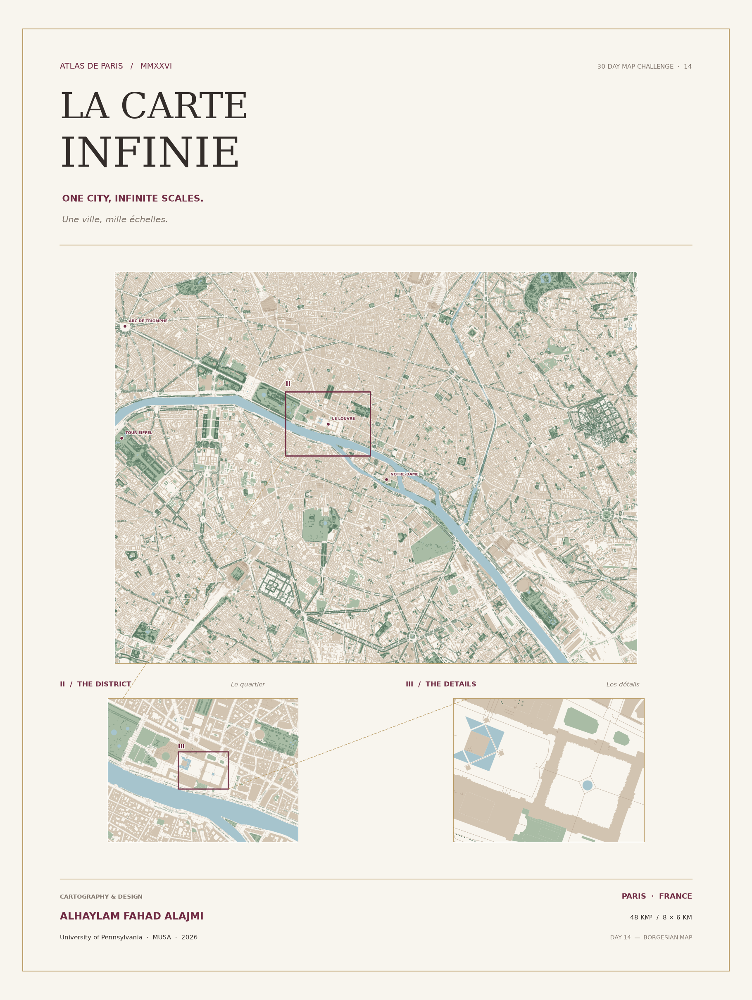

FINAL PARIS POSTER CREATED
PNG: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\exports\Day14_La_Carte_Infinie_Paris_Poster.png
PDF: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\exports\Day14_La_Carte_Infinie_Paris_Poster.pdf
Author: ALHAYLAM FAHAD ALAJMI
Map scales: City → District → Detail


In [44]:

# ============================================================
# CELL 28 | LA CARTE INFINIE — FINAL 2D POSTER
# 30DayMapChallenge 2026 | Day 14 — Borgesian Map
# Cartography & Design: Alhaylam Fahad Alajmi
# ============================================================

from pathlib import Path
import warnings
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

from matplotlib.patches import Rectangle, ConnectionPatch
from shapely.geometry import box

# ============================================================
# 01 | PATHS
# ============================================================

PROJECT_DIR = Path.cwd().resolve().parent
DATA_DIR = PROJECT_DIR / "data"
EXPORTS_DIR = PROJECT_DIR / "exports"
EXPORTS_DIR.mkdir(parents=True, exist_ok=True)

PNG_FILE = EXPORTS_DIR / "Day14_La_Carte_Infinie_Paris_Poster.png"
PDF_FILE = EXPORTS_DIR / "Day14_La_Carte_Infinie_Paris_Poster.pdf"

# ============================================================
# 02 | DESIGN
# ============================================================

IVORY = "#F8F5EE"
PAPER = "#F1EBDD"
BURGUNDY = "#702B43"
GOLD = "#B39256"
INK = "#332D2A"
MUTED = "#81766D"

BUILDINGS = "#D2C4B1"
STREETS = "#B4A18D"
WATER = "#A6C4CD"
GARDENS = "#A9BCA5"
TREES = "#53735E"

CRS = "EPSG:2154"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "savefig.facecolor": IVORY
})

# ============================================================
# 03 | LOAD ORIGINAL DATA
# ============================================================

print("Loading original Paris spatial datasets...")

paths = {
    "streets": DATA_DIR / "paris_streets.gpkg",
    "buildings": DATA_DIR / "paris_buildings.gpkg",
    "water": DATA_DIR / "paris_water.gpkg",
    "gardens": DATA_DIR / "paris_green_spaces.gpkg",
    "trees": DATA_DIR / "paris_trees.gpkg"
}

for name, path in paths.items():
    if not path.exists():
        raise FileNotFoundError(f"Missing {name}: {path}")

# Specify streets layer to avoid the multiple-layer warning.
streets = gpd.read_file(
    paths["streets"],
    layer="streets"
).to_crs(CRS)

buildings = gpd.read_file(paths["buildings"]).to_crs(CRS)
water = gpd.read_file(paths["water"]).to_crs(CRS)
gardens = gpd.read_file(paths["gardens"]).to_crs(CRS)
trees = gpd.read_file(paths["trees"]).to_crs(CRS)

# ============================================================
# 04 | STUDY AREA — 8 × 6 KM
# ============================================================

center = gpd.GeoSeries(
    gpd.points_from_xy([2.3477], [48.8546]),
    crs="EPSG:4326"
).to_crs(CRS).iloc[0]

cx, cy = center.x, center.y

xmin, xmax = cx - 4000, cx + 4000
ymin, ymax = cy - 3000, cy + 3000

study_area = box(xmin, ymin, xmax, ymax)

def prepare(gdf):
    valid = gdf[
        gdf.geometry.notna() &
        ~gdf.geometry.is_empty
    ].copy()
    return valid[valid.intersects(study_area)].copy()

streets = prepare(streets)
buildings = prepare(buildings)
water = prepare(water)
gardens = prepare(gardens)
trees = prepare(trees)

print(f"Buildings: {len(buildings):,}")
print(f"Street segments: {len(streets):,}")
print(f"Trees: {len(trees):,}")

# ============================================================
# 05 | SCALE WINDOWS
# ============================================================

# Both inset maps are centered near the Louvre.
louvre = gpd.GeoSeries(
    gpd.points_from_xy([2.3376], [48.8606]),
    crs="EPSG:4326"
).to_crs(CRS).iloc[0]

lx, ly = louvre.x, louvre.y

# District window
district_half_w = 650
district_half_h = 490

district_bounds = (
    lx - district_half_w,
    ly - district_half_h,
    lx + district_half_w,
    ly + district_half_h
)

# Detail window
detail_half_w = 170
detail_half_h = 128

detail_bounds = (
    lx - detail_half_w,
    ly - detail_half_h,
    lx + detail_half_w,
    ly + detail_half_h
)

# ============================================================
# 06 | MAP DRAWING FUNCTION
# ============================================================

def draw_paris_map(ax, bounds, detail=False):

    bxmin, bymin, bxmax, bymax = bounds
    viewport = box(bxmin, bymin, bxmax, bymax)

    ax.set_facecolor(PAPER)

    def local(gdf):
        return gdf[gdf.intersects(viewport)]

    b = local(buildings)
    s = local(streets)
    g = local(gardens)
    w = local(water)
    t = local(trees)

    if not b.empty:
        b.plot(
            ax=ax,
            color=BUILDINGS,
            edgecolor="none",
            linewidth=0,
            zorder=1,
            rasterized=True
        )

    if not s.empty:
        s.plot(
            ax=ax,
            color=STREETS,
            linewidth=0.40 if detail else 0.17,
            alpha=0.65,
            zorder=2,
            rasterized=True
        )

    if not g.empty:
        g.plot(
            ax=ax,
            color=GARDENS,
            edgecolor="none",
            zorder=3,
            rasterized=True
        )

    if not w.empty:
        w.plot(
            ax=ax,
            color=WATER,
            edgecolor="none",
            zorder=4,
            rasterized=True
        )

    if not t.empty:
        t.plot(
            ax=ax,
            color=TREES,
            markersize=1.4 if detail else 0.12,
            alpha=0.75,
            zorder=5,
            rasterized=True
        )

    ax.set_xlim(bxmin, bxmax)
    ax.set_ylim(bymin, bymax)
    ax.set_aspect("equal")
    ax.axis("off")

    # Frame
    ax.add_patch(
        Rectangle(
            (bxmin, bymin),
            bxmax - bxmin,
            bymax - bymin,
            fill=False,
            edgecolor=GOLD,
            linewidth=1.25,
            zorder=20
        )
    )

# ============================================================
# 07 | POSTER CANVAS
# ============================================================

fig = plt.figure(
    figsize=(18, 24),
    facecolor=IVORY
)

canvas = fig.add_axes([0, 0, 1, 1])
canvas.set_xlim(0, 1)
canvas.set_ylim(0, 1)
canvas.axis("off")

# Outer border
canvas.add_patch(
    Rectangle(
        (0.025, 0.025),
        0.95,
        0.95,
        fill=False,
        edgecolor=GOLD,
        linewidth=1.3
    )
)

# ============================================================
# 08 | HEADER
# ============================================================

fig.text(
    0.075, 0.935,
    "ATLAS DE PARIS   /   MMXXVI",
    fontsize=14,
    color=BURGUNDY
)

fig.text(
    0.925, 0.935,
    "30 DAY MAP CHALLENGE  ·  14",
    fontsize=11,
    color=MUTED,
    ha="right"
)

fig.text(
    0.075, 0.885,
    "LA CARTE",
    fontsize=62,
    fontfamily="DejaVu Serif",
    color=INK
)

fig.text(
    0.075, 0.836,
    "INFINIE",
    fontsize=72,
    fontfamily="DejaVu Serif",
    color=INK
)

fig.text(
    0.078, 0.801,
    "ONE CITY, INFINITE SCALES.",
    fontsize=16,
    color=BURGUNDY,
    weight="bold"
)

fig.text(
    0.078, 0.780,
    "Une ville, mille échelles.",
    fontsize=15,
    color=MUTED,
    style="italic"
)

canvas.plot(
    [0.075, 0.925],
    [0.757, 0.757],
    color=GOLD,
    linewidth=1.1
)

# ============================================================
# 09 | MAIN MAP
# ============================================================

main_ax = fig.add_axes([
    0.075, 0.335,
    0.85, 0.395
])

draw_paris_map(
    main_ax,
    (xmin, ymin, xmax, ymax)
)

# Landmarks
landmarks = [
    ("TOUR EIFFEL", 2.2945, 48.8584),
    ("LE LOUVRE", 2.3376, 48.8606),
    ("NOTRE-DAME", 2.3499, 48.8530),
    ("ARC DE TRIOMPHE", 2.2950, 48.8738)
]

landmark_points = gpd.GeoSeries(
    gpd.points_from_xy(
        [p[1] for p in landmarks],
        [p[2] for p in landmarks]
    ),
    crs="EPSG:4326"
).to_crs(CRS)

for (name, _, _), point in zip(
    landmarks,
    landmark_points
):
    if study_area.covers(point):

        main_ax.scatter(
            point.x,
            point.y,
            s=35,
            color=BURGUNDY,
            edgecolors=IVORY,
            linewidths=1,
            zorder=12
        )

        main_ax.annotate(
            name,
            (point.x, point.y),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=6.5,
            weight="bold",
            color=BURGUNDY,
            path_effects=[
                pe.withStroke(
                    linewidth=2.5,
                    foreground=IVORY
                )
            ],
            zorder=13
        )

# Highlight district extraction
dx0, dy0, dx1, dy1 = district_bounds

main_ax.add_patch(
    Rectangle(
        (dx0, dy0),
        dx1 - dx0,
        dy1 - dy0,
        fill=False,
        edgecolor=BURGUNDY,
        linewidth=2.0,
        zorder=25
    )
)

main_ax.text(
    dx0,
    dy1 + 90,
    "II",
    fontsize=12,
    color=BURGUNDY,
    weight="bold",
    zorder=26,
    path_effects=[
        pe.withStroke(
            linewidth=3,
            foreground=IVORY
        )
    ]
)

# ============================================================
# 10 | DISTRICT INSET
# ============================================================

district_ax = fig.add_axes([
    0.075, 0.155,
    0.385, 0.145
])

draw_paris_map(
    district_ax,
    district_bounds
)

fig.text(
    0.075, 0.312,
    "II  /  THE DISTRICT",
    fontsize=12,
    weight="bold",
    color=BURGUNDY
)

fig.text(
    0.305, 0.312,
    "Le quartier",
    fontsize=11,
    color=MUTED,
    style="italic"
)

# Highlight detail extraction inside district inset
tx0, ty0, tx1, ty1 = detail_bounds

district_ax.add_patch(
    Rectangle(
        (tx0, ty0),
        tx1 - tx0,
        ty1 - ty0,
        fill=False,
        edgecolor=BURGUNDY,
        linewidth=1.8,
        zorder=25
    )
)

district_ax.text(
    tx0,
    ty1 + 20,
    "III",
    fontsize=10,
    color=BURGUNDY,
    weight="bold",
    zorder=26,
    path_effects=[
        pe.withStroke(
            linewidth=2.5,
            foreground=IVORY
        )
    ]
)

# ============================================================
# 11 | DETAIL INSET
# ============================================================

detail_ax = fig.add_axes([
    0.540, 0.155,
    0.385, 0.145
])

draw_paris_map(
    detail_ax,
    detail_bounds,
    detail=True
)

fig.text(
    0.540, 0.312,
    "III  /  THE DETAILS",
    fontsize=12,
    weight="bold",
    color=BURGUNDY
)

fig.text(
    0.810, 0.312,
    "Les détails",
    fontsize=11,
    color=MUTED,
    style="italic"
)

# ============================================================
# 12 | CONNECTED SCALE TRANSITIONS
# ============================================================

# Connect main-map district box to the district inset.
connection_1 = ConnectionPatch(
    xyA=(dx0, dy0),
    coordsA=main_ax.transData,
    xyB=(0.08, 1.0),
    coordsB=district_ax.transAxes,
    color=GOLD,
    linewidth=1.0,
    linestyle=(0, (4, 3)),
    alpha=0.85,
    zorder=30
)

fig.add_artist(connection_1)

# Connect district detail box to the detail inset.
connection_2 = ConnectionPatch(
    xyA=(tx1, ty0),
    coordsA=district_ax.transData,
    xyB=(0.08, 1.0),
    coordsB=detail_ax.transAxes,
    color=GOLD,
    linewidth=1.0,
    linestyle=(0, (4, 3)),
    alpha=0.85,
    zorder=30
)

fig.add_artist(connection_2)

# ============================================================
# 13 | AUTHOR CREDIT & FOOTER
# ============================================================

canvas.plot(
    [0.075, 0.925],
    [0.118, 0.118],
    color=GOLD,
    linewidth=1
)

fig.text(
    0.075, 0.098,
    "CARTOGRAPHY & DESIGN",
    fontsize=10,
    color=MUTED,
    weight="bold"
)

fig.text(
    0.075, 0.077,
    "ALHAYLAM FAHAD ALAJMI",
    fontsize=17,
    color=BURGUNDY,
    weight="bold"
)

fig.text(
    0.075, 0.057,
    "University of Pennsylvania  ·  MUSA  ·  2026",
    fontsize=10.5,
    color=INK
)

fig.text(
    0.925, 0.098,
    "PARIS  ·  FRANCE",
    fontsize=13,
    color=BURGUNDY,
    ha="right",
    weight="bold"
)

fig.text(
    0.925, 0.077,
    "48 KM²  /  8 × 6 KM",
    fontsize=11,
    color=INK,
    ha="right"
)

fig.text(
    0.925, 0.057,
    "DAY 14  —  BORGESIAN MAP",
    fontsize=10,
    color=MUTED,
    ha="right"
)

# ============================================================
# 14 | EXPORT
# ============================================================

print("Exporting final 2D poster...")

fig.savefig(
    PNG_FILE,
    dpi=200,
    facecolor=IVORY,
    bbox_inches=None,
    pad_inches=0
)

fig.savefig(
    PDF_FILE,
    facecolor=IVORY,
    bbox_inches=None,
    pad_inches=0,
    dpi=200
)

plt.show()
plt.close(fig)

print("=" * 60)
print("FINAL PARIS POSTER CREATED")
print("=" * 60)
print(f"PNG: {PNG_FILE}")
print(f"PDF: {PDF_FILE}")
print("Author: ALHAYLAM FAHAD ALAJMI")
print("Map scales: City → District → Detail")
print("=" * 60)



## 29 | Conclusion & Limitations

### Conclusion

*La Carte Infinie — Paris* explores the idea of a Borgesian map through multiple levels of urban detail. Instead of presenting Paris at only one scale, the project moves from a city-wide view to individual buildings, streets, trees, and landmarks.

The interactive 3D map allows users to explore these features by zooming and changing the viewing angle. The accompanying 2D poster presents the same concept through three connected maps: the city, the district, and the details.

Together, these visualizations show how changing the map scale can change what we notice about a city.

### Limitations

- **Building heights:** The 3D buildings use a uniform illustrative height of 15 meters. They do not represent actual measured building heights.
- **Data completeness:** OpenStreetMap features may be missing or unevenly mapped across the study area.
- **Map boundaries:** The highlighted 8 × 6 km study area is a visual reference. The interactive map also allows users to explore beyond this boundary.
- **Level of detail:** Some features become visible only at closer zoom levels to keep the interactive map readable.
- **Interpretation:** This project is a creative cartographic interpretation of the Borgesian map concept, not a geographically exhaustive or 1:1 representation of Paris.

### Final Outputs

1. Interactive 3D map of Paris (HTML)
2. Editorial 2D poster (PNG and PDF)
3. Jupyter notebook documenting the workflow

**Cartography & Design:** Alhaylam Fahad Alajmi  
**Project:** 30DayMapChallenge 2026 — Day 14: Borgesian Map  
**Program:** Master of Urban Spatial Analytics, University of Pennsylvania


In [48]:

# ============================================================
# 30 | FINAL EXPORT VERIFICATION
# Day 14 — La Carte Infinie | Paris
# Author: Alhaylam Fahad Alajmi
# ============================================================

from pathlib import Path

PROJECT_DIR = Path.cwd().resolve().parent
EXPORTS_DIR = PROJECT_DIR / "exports"

required_files = {
    "Interactive 3D Map (HTML)":
        "Paris_La_Carte_Infinie_PUBLISH.html",

    "2D Poster (PNG)":
        "Day14_La_Carte_Infinie_Paris_Poster.png",

    "2D Poster (PDF)":
        "Day14_La_Carte_Infinie_Paris_Poster.pdf",
}

print("=" * 65)
print("DAY 14 | FINAL EXPORT VERIFICATION")
print("LA CARTE INFINIE — PARIS")
print("=" * 65)

all_found = True

for label, filename in required_files.items():

    file_path = EXPORTS_DIR / filename

    if file_path.is_file() and file_path.stat().st_size > 0:

        size_mb = file_path.stat().st_size / (1024 * 1024)

        print(f"[OK] {label}")
        print(f"     File: {filename}")
        print(f"     Size: {size_mb:.2f} MB")
        print()

    else:

        print(f"[MISSING] {label}")
        print(f"          File: {filename}")
        print()

        all_found = False

print("=" * 65)

if all_found:
    print("SUCCESS — All required exports are present.")
else:
    print("ACTION REQUIRED — Some exports are missing.")

print("=" * 65)

print(f"Export folder: {EXPORTS_DIR}")
print("Project: La Carte Infinie — Paris")
print("Challenge: 30DayMapChallenge 2026 | Day 14")
print("Author: Alhaylam Fahad Alajmi")


DAY 14 | FINAL EXPORT VERIFICATION
LA CARTE INFINIE — PARIS
[OK] Interactive 3D Map (HTML)
     File: Paris_La_Carte_Infinie_PUBLISH.html
     Size: 34.48 MB

[OK] 2D Poster (PNG)
     File: Day14_La_Carte_Infinie_Paris_Poster.png
     Size: 9.21 MB

[OK] 2D Poster (PDF)
     File: Day14_La_Carte_Infinie_Paris_Poster.pdf
     Size: 6.29 MB

SUCCESS — All required exports are present.
Export folder: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\exports
Project: La Carte Infinie — Paris
Challenge: 30DayMapChallenge 2026 | Day 14
Author: Alhaylam Fahad Alajmi


In [47]:

# 31 | FIND INTERACTIVE MAP EXPORTS

from pathlib import Path

PROJECT_DIR = Path.cwd().resolve().parent
EXPORTS_DIR = PROJECT_DIR / "exports"

html_files = sorted(EXPORTS_DIR.glob("*.html"))

print("DAY 14 | AVAILABLE HTML MAPS")
print("=" * 55)

if html_files:
    for file in html_files:
        size_mb = file.stat().st_size / (1024 * 1024)
        print(f"{file.name}  |  {size_mb:.2f} MB")
else:
    print("No HTML files found in exports.")

print("=" * 55)


DAY 14 | AVAILABLE HTML MAPS
Paris_La_Carte_Infinie_PUBLISH.html  |  34.48 MB


In [49]:

# ============================================================
# 32 | CREATE DAY 14 README
# La Carte Infinie — Paris
# ============================================================

from pathlib import Path

PROJECT_DIR = Path.cwd().resolve().parent
README_FILE = PROJECT_DIR / "README.md"

readme = """# La Carte Infinie — Paris

**30DayMapChallenge 2026 | Day 14 — Borgesian Map**

*One city, infinite scales. / Une ville, mille échelles.*

## Project Overview

La Carte Infinie explores Paris through multiple levels of geographic detail.

Inspired by the Borgesian Map theme, the project moves from a city-wide perspective to individual urban features, revealing how a city changes as the viewing scale changes.

The project includes an interactive 3D map and a 2D editorial poster.

## Interactive Map

[Explore La Carte Infinie — Paris](exports/Paris_La_Carte_Infinie_PUBLISH.html)

The interactive map includes:

- 3D building footprints
- Streets and the Seine River
- Parks and individual trees
- Selected Paris landmarks
- Zoom-dependent map details
- Interactive navigation and camera controls

**Note:** Building heights are illustrative (15 meters), not measured heights.

## Final Poster

![La Carte Infinie — Paris](exports/Day14_La_Carte_Infinie_Paris_Poster.png)

The poster presents three connected geographic scales:

1. **The City** — Paris study area
2. **The District** — Louvre neighborhood
3. **The Details** — Individual urban features

[Download Poster PDF](exports/Day14_La_Carte_Infinie_Paris_Poster.pdf)

## Study Area

- Location: Paris, France
- Approximate area: 48 km²
- Study extent: 8 × 6 km
- Coordinate reference system for spatial analysis: EPSG:2154

## Data and Tools

- OpenStreetMap geographic features
- Python and GeoPandas
- Shapely and Matplotlib
- MapLibre GL JS
- Jupyter Notebook

## Limitations

OpenStreetMap data completeness varies across locations. The interactive building heights are illustrative, and the highlighted study boundary does not restrict navigation beyond the study area.

## Author

**Alhaylam Fahad Alajmi**

Master of Urban Spatial Analytics (MUSA)  
University of Pennsylvania

**30DayMapChallenge 2026**
"""

README_FILE.write_text(readme, encoding="utf-8")

print("=" * 60)
print("DAY 14 | README CREATED")
print("=" * 60)
print(f"File: {README_FILE}")
print(f"Size: {README_FILE.stat().st_size:,} bytes")
print("=" * 60)


DAY 14 | README CREATED
File: C:\Users\Alhaylam Alajmi\Desktop\Riyadh-30DayMapChallenge-2026\Riyadh-30DayMapChallenge-2026\maps\day14_borgesian_map\README.md
Size: 1,960 bytes


In [50]:

# ============================================================
# 33 | DAY 14 PROJECT STRUCTURE CHECK
# ============================================================

from pathlib import Path

PROJECT_DIR = Path.cwd().resolve().parent

print("=" * 65)
print("DAY 14 | PROJECT STRUCTURE")
print("=" * 65)

for item in sorted(PROJECT_DIR.iterdir()):
    if item.is_dir():
        print(f"[FOLDER] {item.name}/")
        if item.name == "exports":
            for file in sorted(item.iterdir()):
                if file.is_file():
                    size_mb = file.stat().st_size / (1024 * 1024)
                    print(f"    [FILE] {file.name} ({size_mb:.2f} MB)")
    elif item.is_file():
        size_mb = item.stat().st_size / (1024 * 1024)
        print(f"[FILE] {item.name} ({size_mb:.2f} MB)")

print("=" * 65)
print("PROJECT STRUCTURE CHECK COMPLETED")


DAY 14 | PROJECT STRUCTURE
[FOLDER] code/
[FOLDER] data/
[FOLDER] exports/
    [FILE] Day14_La_Carte_Infinie_Paris_Poster.pdf (6.29 MB)
    [FILE] Day14_La_Carte_Infinie_Paris_Poster.png (9.21 MB)
    [FILE] Paris_La_Carte_Infinie_PUBLISH.html (34.48 MB)
[FILE] README.md (0.00 MB)
PROJECT STRUCTURE CHECK COMPLETED
